## DESI: desarrollo y evaluación en Validation del candidato neuronal A–G

Estimación de masa estelar, tasa de formación estelar y D4000

Instituto Tecnológico y de Estudios Superiores de Monterrey (ITESM) · Equipo 24

José Florencio Maguey Peralta — A01796727  
Erick Alberto Bustos Cruz — A01378966  
Luz Copelia Minutti Pérez — A01796921

Asesores científicos: Dr. Héctor Hernández Toledo y Dr. José Antonio Vázquez Mata.  
Asesor ITESM: Dr. Iván Reyes Amezcua.

En este trabajo desarrollamos un modelo neuronal para estimar tres propiedades de galaxias a partir de imágenes de DESI Legacy Imaging Surveys. Partimos de ResNet50 y estudiamos cómo cambiaban las predicciones al compartir el extractor entre tareas, incorporar el redshift, modificar la representación de las bandas y utilizar una función de pérdida menos sensible a errores grandes. Reunimos estas decisiones en siete variantes, identificadas de A a G, que forman parte del desarrollo de una misma familia de modelos.

Trabajamos con las etiquetas `log_mstar`, `log_sfr` y `d4000` del catálogo del experimento. Interpretamos las dos primeras como logaritmos decimales de la masa estelar, en masas solares, y de la tasa de formación estelar, en masas solares por año. Reportamos sus errores en dex. Para D4000 conservamos la definición del catálogo y expresamos los errores en unidades adimensionales. Nuestro objetivo fue reproducir estas estimaciones de referencia; no las consideramos mediciones físicas libres de incertidumbre.

Comparamos las variantes sobre una muestra común de 9 299 galaxias y repetimos cada una con las semillas 42, 7 y 2026. Completamos 21 corridas de variante, equivalentes a 27 entrenamientos de red, porque A utilizó una red por propiedad y B–G utilizaron una red multitarea. Inicializamos los extractores con pesos de ImageNet1K V1 y entrenamos nuevas cabezas de regresión. Por tanto, utilizamos transferencia de aprendizaje, aunque iniciamos este proyecto sin recuperar modelos de otras fases.

En este notebook cerramos el desarrollo del candidato neuronal con los resultados de Train y Validation. Las siete variantes A–G nos permiten elegir una configuración de ResNet50 para incorporarla como uno de los seis candidatos individuales del proyecto. Compararemos los seis algoritmos con el mismo criterio de Validation, ajustaremos los dos de mejor desempeño y elegiremos un único modelo final. La evaluación en Test corresponderá a ese modelo, en una etapa posterior; esta ejecución termina antes de realizarla.

## Declaración de IA

Empleamos ChatGPT con el modelo GPT-6 como apoyo para elaborar la estructura inicial del código y desarrollar el planteamiento de la arquitectura. Trabajamos su diseño mediante interacciones sucesivas de revisión, control y mejora, en las que discutimos alternativas y ajustamos las propuestas a las necesidades del proyecto. Como equipo, nos encargamos de integrar, adaptar e implementar el código, tomando como punto de partida el marco proporcionado por GPT.

La incorporación del redshift como predictor fue sugerida por el Dr. Iván Reyes Amezcua. A partir de su propuesta, trabajamos con el Dr. Héctor Hernández Toledo y el Dr. José Antonio Vázquez Mata para definir cómo integrarlo, considerando el origen de las etiquetas y las correcciones astronómicas aplicadas durante su obtención. Esta revisión nos permitió distinguir entre utilizar el redshift como información adicional para el modelo y aplicar correcciones a las cantidades de referencia.

También desarrollamos una representación alternativa de las imágenes para estudiar el efecto del tratamiento de las bandas. Comparamos las composiciones RGB de Lupton con las bandas g, r y z procesadas mediante una transformación asinh y una estandarización calculada exclusivamente con Train. Buscamos determinar si conservar los valores de las bandas, incluidos los negativos, permitía mejorar las predicciones frente a la representación RGB.

Finalmente, estudiamos y evaluamos el error cuadrático medio (MSE) y la función de pérdida Huber, que reduce la influencia relativa de los errores grandes durante el entrenamiento. Estas decisiones formaron parte de nuestro trabajo técnico, apoyado por las interacciones con GPT y por la orientación científica de los asesores. El uso de IA acompañó el desarrollo, mientras que la implementación, la revisión de los resultados y las decisiones metodológicas quedaron bajo nuestra responsabilidad como equipo.

## 1 · Diseño de la comparación

Organizamos el experimento para que los cambios de desempeño pudieran relacionarse con decisiones concretas del modelo. Conservamos los mismos identificadores, etiquetas y particiones en las siete variantes. También mantuvimos el recorte espacial, el optimizador, el calendario de entrenamiento y los aumentos, de modo que estas condiciones no cambiaran entre A y G.

| Decisión | Cómo la aplicamos | Por qué la mantuvimos |
|---|---|---|
| Muestra común | Utilizamos las mismas 9 299 galaxias en todas las variantes. | Evitamos comparar resultados obtenidos con poblaciones distintas. |
| Preparación con Train | Calculamos las escalas de GRZ, etiquetas y redshift únicamente con entrenamiento. | Evitamos que las estadísticas de Validation y Test intervinieran en el ajuste de las transformaciones. |
| Tres repeticiones | Entrenamos con 42, 7 y 2026 en las siete variantes. | Observamos cuánto variaban los resultados al cambiar la inicialización y los aumentos. |
| Evaluación completa | Conservamos todas las variantes después de la primera semilla. | Dimos a cada alternativa el mismo número de repeticiones. |
| Criterio global común | Promediamos el MSE normalizado entre propiedades y después entre semillas. | Comparamos las variantes con una misma regla, incluso cuando entrenamos con Huber. |
| Candidato neuronal sin ensamble | Conservamos la semilla 42 de la variante seleccionada. | Representamos a esta familia con una sola red para compararla con los otros cinco candidatos. |

Las semillas nos permitieron describir la estabilidad del entrenamiento con una partición fija. No las tratamos como pliegues de validación cruzada ni como nuevas galaxias, y tampoco promediamos sus predicciones. 

## 2 · Variantes que evaluamos

Construimos las variantes para responder preguntas sobre el aprendizaje de las tres propiedades. En A entrenamos tres ResNet50 independientes. En B–G compartimos un extractor y colocamos una cabeza de regresión por propiedad. Las tres cabezas produjeron sus salidas en paralelo; no utilizamos la masa predicha como entrada de SFR ni la SFR predicha como entrada de D4000.

| Variante | Arquitectura | Representación de imagen | Redshift como predictor | Pérdida de entrenamiento |
|---|---|---|---|---|
| A · `A_ind_rgb_mse` | Tres redes independientes | RGB Lupton | No | MSE |
| B · `B_multi_rgb_mse` | Extractor compartido y tres cabezas | RGB Lupton | No | MSE |
| C · `C_multi_rgb_z_mse` | Extractor compartido y tres cabezas | RGB Lupton | Sí | MSE |
| D · `D_multi_grz_z_mse` | Extractor compartido y tres cabezas | GRZ con asinh y estandarización | Sí | MSE |
| E · `E_multi_grz_z_huber` | Extractor compartido y tres cabezas | GRZ con asinh y estandarización | Sí | Huber |
| F · `F_multi_grz_mse` | Extractor compartido y tres cabezas | GRZ con asinh y estandarización | No | MSE |
| G · `G_multi_grz_huber` | Extractor compartido y tres cabezas | GRZ con asinh y estandarización | No | Huber |

Para interpretar los cambios utilizamos los siguientes contrastes, manteniendo las mismas galaxias en cada par:

| Comparación | Pregunta que estudiamos |
|---|---|
| A → B | ¿Qué cambia al compartir el extractor entre las tres tareas? |
| B → C | ¿Qué aporta el redshift cuando usamos RGB y MSE? |
| C → D | ¿Qué cambia al pasar de RGB a GRZ con redshift y MSE? |
| D → E | ¿Qué cambia al sustituir MSE por Huber con GRZ y redshift? |
| B → F | ¿Qué cambia al pasar de RGB a GRZ sin redshift y con MSE? |
| F → G | ¿Qué cambia al utilizar Huber con GRZ sin redshift? |
| F → D | ¿Qué aporta el redshift con GRZ y MSE? |
| G → E | ¿Qué aporta el redshift con GRZ y Huber? |

Interpretamos estos pares dentro de su configuración. Al pasar de RGB a GRZ cambiamos conjuntamente la composición, el orden de canales y la normalización. Al pasar de A a B también cambiamos el número total de parámetros y la posibilidad de elegir una época distinta para cada tarea. Por estas razones, no atribuimos cada diferencia a un único mecanismo aislado.

Usamos A como referencia de redes independientes, no como una reproducción exacta de Katachi.


## 3 · Entorno de trabajo y configuración utilizada

Ejecutamos el experimento en el servidor del proyecto, con Python 3.12.3, PyTorch 2.8.0 con CUDA 12.6, torchvision 0.23.0 y una GPU NVIDIA RTX A4000. Conservamos el entorno de Jupyter disponible y configuramos cuBLAS antes de utilizar CUDA. Registramos las versiones y las rutas para poder identificar la ejecución y recuperar sus resultados.

Concentramos en `CFG` las decisiones comunes a A–G. La siguiente tabla recoge los valores efectivos del entrenamiento y el criterio con el que justificamos su uso. Para contextualizar la escala de cada elección incluimos candidatos menores y mayores plausibles. Los presentamos como referencias orientativa. 

| Parámetro | Valor utilizado | Candidatos orientativos menor / mayor, sin corridas documentadas | Justificación del valor utilizado |
|---|---|---|---|
| Imágenes por lote | 16 | 8 / 32 | Trabajamos con recortes de 300 × 300 y ajuste fino de ResNet50; elegimos un lote contenido para administrar la memoria de la GPU. |
| Acumulación de gradientes | 2 lotes | 1 / 4 | Reunimos normalmente 32 imágenes por actualización sin mantenerlas simultáneamente en memoria. |
| Tasa inicial de las cabezas | 3 × 10⁻⁴ | 1 × 10⁻⁴ / 1 × 10⁻³ | Permitimos que las capas nuevas aprendieran más rápido que el extractor preentrenado. |
| Tasa inicial del extractor | 3 × 10⁻⁵ | 1 × 10⁻⁵ / 1 × 10⁻⁴ | Aplicamos cambios diez veces menores al inicio para adaptar las características preentrenadas de forma gradual. |
| Decaimiento de pesos de AdamW | 1 × 10⁻⁴ | 1 × 10⁻⁵ / 1 × 10⁻³ | Añadimos regularización sobre los pesos durante el ajuste. |
| Máximo de épocas | 100 | 50 / 150 | Establecimos un límite amplio y dejamos que la validación determinara qué época conservar. |
| Épocas iniciales con solo cabezas | 5 | 3 / 10 | Dimos un primer periodo de adaptación a las salidas antes de modificar el extractor. |
| Última época con solo `layer4` y cabezas abiertas | 15 | 10 / 20 | Introdujimos una etapa intermedia antes del ajuste completo desde la época 16. |
| Época mínima para permitir la parada temprana | 25 | 20 / 30 | Dejamos que la red pasara por las tres etapas antes de detenerla por falta de mejora. |
| Paciencia de parada | 12 épocas | 8 / 16 | Toleramos varios ciclos sin una mejora suficiente antes de finalizar. |
| Mejora mínima para reiniciar la paciencia | 1 × 10⁻⁴ | 1 × 10⁻⁵ / 1 × 10⁻³ | Evitamos que oscilaciones muy pequeñas reiniciaran continuamente el contador. |
| Paciencia del ajuste de tasa | 4 épocas | 2 / 6 | Permitimos reducir la tasa antes de agotar la paciencia de parada. |
| Límite de norma del gradiente | 5 | 1 / 10 | Acotamos actualizaciones con gradientes excepcionalmente grandes. |

Utilizamos AdamW para adaptar las tasas por parámetro y aplicar el decaimiento de pesos de forma desacoplada. Cuando Validation dejó de mejorar, empleamos `ReduceLROnPlateau` para multiplicar las tasas por 0.5, con un mínimo de 1 × 10⁻⁷. Estos valores quedaron fijos entre variantes. 

Activamos precisión mixta para aprovechar la GPU y fijamos `num_workers=0` para realizar la carga desde el proceso de Jupyter. En evaluación utilizamos float32. Conservamos las semillas 42, 7 y 2026 en todas las alternativas, y fijamos 42 como la semilla del modelo que guardaríamos al cerrar la selección.

Guardamos los archivos bajo `~/DESI_experimentos_mejorados/desi_comparacion_A_G_v01/<firma>`. La firma de muestra y las firmas de corrida nos permitieron identificar qué datos y configuración correspondían a cada resultado.

Mantuvimos `evaluar_test=False` y limitamos las funciones de predicción de este notebook a Train y Validation. Seleccionar una variante dentro de A–G no habilita la evaluación en Test: primero completaremos la comparación de los seis candidatos, ajustaremos los dos mejores y elegiremos el modelo individual final.

In [1]:
# MEJORAS M01–M03: reproducibilidad, rutas locales y protocolo explícito.
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
import sys, importlib.util
requeridos = ['numpy', 'pandas', 'matplotlib', 'astropy', 'torch', 'torchvision', 'PIL', 'IPython']
faltan = [x for x in requeridos if importlib.util.find_spec(x) is None]
if faltan:
    raise RuntimeError('Faltan paquetes en ' + sys.executable + ': ' + ', '.join(faltan) +
                       '. Usa el kernel del experimento anterior. No se reinstala PyTorch automáticamente.')
import json, math, time, random, hashlib, re, gc, copy, platform, warnings, uuid, zipfile
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from astropy.io import fits
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from astropy.visualization import make_lupton_rgb
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from IPython.display import display, FileLink

VERSION = 'DESI_COMPARACION_A_G_2.0.0'
OBJETIVOS = ['log_mstar', 'log_sfr', 'd4000']
ERRORES = ['error_log_mstar', 'error_log_sfr', 'error_d4000']
PARTICIONES = ['Train', 'Validation', 'Test']

BASE_DATOS = Path.home() / 'DESI_Candidatas_800_GRZ'
CFG = dict(
    base_datos=str(BASE_DATOS), catalogo_csv='', carpeta_fits='',
    carpeta_resultados=str(Path.home() / 'DESI_experimentos_mejorados'),
    nombre_proyecto='desi_comparacion_A_G_v01',
    fase='Nueva ejecución conjunta del diseño A–G; todas las variantes y semillas',
    test_consultado_en_fase_previa=True,
    petro90_csv='',  # Opcional: ruta de petro90.csv; se intenta BASE_DATOS/petro90.csv.
    id_petro90='MANGAID', columna_petro90='PETRO_TH90',
    # Opcional: CSV con mangaid y ruta_ivar_g/r/z, ruta_nexp_g/r/z y/o ruta_maskbits.
    # Deben ser mapas de 800x800 ALINEADOS con el cubo. No se descargan ni se infieren.
    mapas_csv='', hdu_mapas=0,
    exclusiones_adicionales_csv='',  # Opcional: mangaid,motivo; decisión documentada, nunca por residuo.
    hdu_fits=0, bandas_sin_header=None, evidencia_bandas='',
    lado_original=800, lado_centro=300, escala_arcsec=0.262,
    tolerancia_escala=1e-4, tolerancia_centro_pix=0.5,
    rgb_Q=8.0, rgb_stretch=0.5,
    pesos_imagenet_local='',  # Opcional: archivo oficial resnet50-0676ba61.pth ya descargado.
    usar_gpu=True, batch_size=16, acumulacion=2, num_workers=0,
    max_epocas=100, epocas_solo_salidas=5, epocas_hasta_abrir_toda_red=15,
    lr_salidas=3e-4, lr_backbone=3e-5, weight_decay=1e-4,
    paciencia=12, mejora_minima=1e-4, paciencia_lr=4,
    min_epocas_antes_parada=25, huber_delta=1.0,
    precision_mixta=True, grad_clip=5.0, semilla_inicial=42,
    # Siete variantes, TODAS con las tres semillas: 21 corridas / 27 redes individuales.
    variantes=['A_ind_rgb_mse','B_multi_rgb_mse','C_multi_rgb_z_mse',
               'D_multi_grz_z_mse','E_multi_grz_z_huber',
               'F_multi_grz_mse','G_multi_grz_huber'],
    semillas_adicionales=[7, 2026],
    bootstrap_repeticiones=1000,
    # Esta etapa termina en Validation. Test se evaluará en otro notebook, con el modelo final de los seis candidatos.
    evaluar_test=False,
)
VARIANTES = {
    'A_ind_rgb_mse': dict(arquitectura='independiente', entrada='RGB', redshift=False, perdida='MSE'),
    'B_multi_rgb_mse': dict(arquitectura='compartida', entrada='RGB', redshift=False, perdida='MSE'),
    'C_multi_rgb_z_mse': dict(arquitectura='compartida', entrada='RGB', redshift=True, perdida='MSE'),
    'D_multi_grz_z_mse': dict(arquitectura='compartida', entrada='GRZ', redshift=True, perdida='MSE'),
    'E_multi_grz_z_huber': dict(arquitectura='compartida', entrada='GRZ', redshift=True, perdida='HUBER'),
    'F_multi_grz_mse': dict(arquitectura='compartida', entrada='GRZ', redshift=False, perdida='MSE'),
    'G_multi_grz_huber': dict(arquitectura='compartida', entrada='GRZ', redshift=False, perdida='HUBER'),
}
EXCLUSIONES_CONOCIDAS = {
    g: 'Banda completa a cero en la entrada central; exclusión del experimento previo conservada.'
    for g in ['1-290015','1-390056','1-626493']
}

def sha_archivo(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(4*1024*1024), b''): h.update(b)
    return h.hexdigest()

def firma(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, ensure_ascii=False,
        default=lambda x: x.item() if isinstance(x, np.generic) else str(x)).encode()).hexdigest()

def escribir_json(obj, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_name(path.name+'.tmp')
    with open(temp, 'w', encoding='utf-8') as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=lambda x: x.item() if isinstance(x,np.generic) else str(x))
        f.flush(); os.fsync(f.fileno())
    os.replace(temp, path)

def escribir_csv(tabla, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_name(path.name+'.tmp')
    tabla.to_csv(temp,index=False); os.replace(temp,path)

def fijar_semilla(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)

def versiones():
    import astropy, torchvision
    return dict(python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,
                torch=torch.__version__,torchvision=torchvision.__version__,astropy=astropy.__version__,
                cuda=torch.version.cuda,dispositivo=torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

def resolver_rutas(cfg):
    base = Path(cfg['base_datos']).expanduser()
    if not base.is_dir():
        opciones = [p for p in Path.home().iterdir() if p.is_dir() and p.name.casefold()=='desi_candidatas_800_grz']
        if len(opciones)==1: base=opciones[0]
        else: raise FileNotFoundError('ACTUALIZA CFG["base_datos"]. No existe '+str(base))
    if cfg['catalogo_csv']:
        cat=Path(cfg['catalogo_csv']).expanduser()
    else:
        posibles=list(dict.fromkeys(p.resolve() for folder in [base,Path.cwd(),Path.home()]
            for name in ['catalogo_candidato_9661_galaxias.csv','catalogo_candidatas_original.csv']
            if (p:=folder/name).is_file()))
        if not posibles: raise FileNotFoundError('Sube el catálogo CSV a '+str(base)+' o ACTUALIZA catalogo_csv.')
        if len({sha_archivo(p) for p in posibles})>1:
            raise ValueError('Hay catálogos diferentes. Especifica catalogo_csv: '+str(posibles))
        cat=posibles[0]
    if not cat.is_file(): raise FileNotFoundError(str(cat))
    if cfg['carpeta_fits']:
        carpeta=Path(cfg['carpeta_fits']).expanduser()
    else:
        posibles=[base/'descarga_22fb149046f162f3'/'fits',base/'descarga_22fb149046f162f3 (1)'/'fits',base/'fits']
        posibles=[p for p in posibles if p.is_dir()]
        if len(posibles)!=1: raise ValueError('ACTUALIZA carpeta_fits con el directorio de cubos 800px: '+str(posibles))
        carpeta=posibles[0]
    if not carpeta.is_dir(): raise FileNotFoundError(str(carpeta))
    cfg.update(base_datos=str(base.resolve()), catalogo_csv=str(cat.resolve()),carpeta_fits=str(carpeta.resolve()))
    if not cfg['petro90_csv'] and (base/'petro90.csv').is_file(): cfg['petro90_csv']=str(base/'petro90.csv')
    return cfg

def preparar_catalogo(cfg):
    cfg=resolver_rutas(cfg)
    cat=pd.read_csv(cfg['catalogo_csv'],dtype={'mangaid':'string'},encoding='utf-8-sig')
    necesarias={'mangaid','split_proyecto','QCFLAG_original','RA_Pipe3D','DEC_Pipe3D','redshift',*OBJETIVOS}
    if not necesarias.issubset(cat): raise ValueError('Faltan columnas: '+str(necesarias-set(cat)))
    cat['mangaid']=cat.mangaid.str.strip();cat['particion']=cat.split_proyecto.astype('string').str.strip()
    if cat.mangaid.isna().any() or cat.mangaid.duplicated().any() or not cat.mangaid.str.fullmatch(r'\d+-\d+').all():
        raise ValueError('Identificadores ausentes, repetidos o no interpretables.')
    if not cat.particion.isin(PARTICIONES).all(): raise ValueError('Particiones no reconocidas; no se reasignan.')
    for c in ['QCFLAG_original','RA_Pipe3D','DEC_Pipe3D','redshift',*OBJETIVOS,*ERRORES]:
        if c not in cat: cat[c]=np.nan
        cat[c]=pd.to_numeric(cat[c],errors='coerce')
    excl=dict(EXCLUSIONES_CONOCIDAS)
    if cfg['exclusiones_adicionales_csv']:
        e=pd.read_csv(cfg['exclusiones_adicionales_csv'],dtype='string',keep_default_na=False)
        if not {'mangaid','motivo'}.issubset(e) or e.mangaid.duplicated().any() or e.motivo.str.strip().eq('').any():
            raise ValueError('Exclusiones adicionales: se requieren ID únicos y motivo.')
        if not e.mangaid.isin(cat.mangaid).all(): raise ValueError('Exclusión de ID ajeno al catálogo.')
        excl.update(dict(zip(e.mangaid,e.motivo)))
    cat['motivo_exclusion']=''
    def marcar(cond,texto):
        cat.loc[cond,'motivo_exclusion']+=texto+'; '
    marcar(~cat.QCFLAG_original.eq(0),'QCFLAG distinto de cero o no interpretable')
    marcar(~np.isfinite(cat[OBJETIVOS]).all(axis=1),'Etiqueta no finita')
    marcar(~np.isfinite(cat[['RA_Pipe3D','DEC_Pipe3D']]).all(axis=1)|~cat.RA_Pipe3D.between(0,360,inclusive='left')|~cat.DEC_Pipe3D.between(-90,90),'Coordenadas no utilizables')
    # Muestra común para las variantes con y sin redshift; se registra la restricción.
    marcar(~np.isfinite(cat.redshift)|cat.redshift.le(0),'Redshift no utilizable para muestra común')
    for g,m in excl.items(): marcar(cat.mangaid.eq(g),m)
    cat['r90_arcsec']=np.nan
    if cfg['petro90_csv']:
        r=pd.read_csv(cfg['petro90_csv'],dtype={cfg['id_petro90']:'string'})
        if not {cfg['id_petro90'],cfg['columna_petro90']}.issubset(r): raise ValueError('Revisa columnas del archivo Petro90.')
        ids=r[cfg['id_petro90']].str.strip()
        if ids.duplicated().any(): raise ValueError('Petro90 contiene ID repetidos.')
        valores=pd.to_numeric(r[cfg['columna_petro90']],errors='coerce')
        cat['r90_arcsec']=cat.mangaid.map(dict(zip(ids,valores))).where(lambda s: np.isfinite(s)&s.gt(0))
    muestra=cat.loc[cat.motivo_exclusion.eq('')].copy().sort_values('mangaid').reset_index(drop=True)
    if any(muestra.particion.eq(x).sum()<2 for x in PARTICIONES): raise ValueError('Partición vacía o insuficiente.')
    # Las decisiones generan una carpeta distinta; nunca se sobreescribe el experimento anterior.
    doc={'version':VERSION,'catalogo_sha':sha_archivo(cfg['catalogo_csv']),
         'muestra':muestra[['mangaid','particion',*OBJETIVOS,'redshift']].to_dict('records'),
         'exclusiones':excl,'geometria':[cfg[k] for k in ['lado_original','lado_centro','escala_arcsec']]}
    salida=Path(cfg['carpeta_resultados']).expanduser()/cfg['nombre_proyecto']/firma(doc)[:12]
    salida.mkdir(parents=True,exist_ok=True)
    escribir_json(cfg,salida/'configuracion.json');escribir_json(doc,salida/'definicion_muestra.json')
    escribir_json(dict(version=VERSION,fase=cfg['fase'],variantes=cfg['variantes'],
        semillas=[cfg['semilla_inicial'],*cfg['semillas_adicionales']],
        inicializacion='ImageNet1K V1 y cabezas nuevas; sin checkpoints de otras fases',
        test_consultado_en_fase_previa=cfg['test_consultado_en_fase_previa']),
        salida/'protocolo_A_G.json')
    escribir_csv(cat,salida/'catalogo_auditado.csv');escribir_csv(cat.loc[cat.motivo_exclusion.ne('')],salida/'exclusiones.csv')
    display(cat.groupby(['particion','QCFLAG_original'],dropna=False).size().rename('galaxias').reset_index())
    display(muestra.groupby('particion').size().rename('muestra_comun').to_frame())
    print('Muestra común:',len(muestra),'| Resultados:',salida)
    return muestra,salida

In [2]:
print('Python:',sys.executable)
print('Versiones:',versiones())
print('Resultados nuevos:',Path(CFG['carpeta_resultados'])/CFG['nombre_proyecto'])

print('Variantes:', CFG['variantes'])
print('Semillas para TODAS:', [CFG['semilla_inicial'], *CFG['semillas_adicionales']])
print('Diseño: 21 corridas de variante / 27 redes individuales. Test desactivado.')


Python: /home/a01796921/katachi-env/bin/python
Versiones: {'python': '3.12.3', 'numpy': '2.5.3', 'pandas': '3.0.6', 'torch': '2.8.0+cu126', 'torchvision': '0.23.0+cu126', 'astropy': '8.0.1', 'cuda': '12.6', 'dispositivo': 'NVIDIA RTX A4000'}
Resultados nuevos: /home/a01796921/DESI_experimentos_mejorados/desi_comparacion_A_G_v01
Variantes: ['A_ind_rgb_mse', 'B_multi_rgb_mse', 'C_multi_rgb_z_mse', 'D_multi_grz_z_mse', 'E_multi_grz_z_huber', 'F_multi_grz_mse', 'G_multi_grz_huber']
Semillas para TODAS: [42, 7, 2026]
Diseño: 21 corridas de variante / 27 redes individuales. Test desactivado.


## 4 · Construcción de la muestra común

Partimos de un catálogo de 9 661 candidatas. Conservamos las galaxias con `QCFLAG_original=0`, las tres etiquetas finitas, coordenadas utilizables y redshift finito positivo. Mantuvimos las particiones de `split_proyecto`; no reasignamos las galaxias para favorecer alguna variante. Aplicamos el requisito de redshift también a las redes que no lo recibieron como predictor, porque necesitábamos comparar exactamente la misma muestra.

Conservamos las exclusiones registradas para `1-290015`, `1-390056` y `1-626493`, asociadas a una banda completamente a cero dentro del recorte central. Registramos los motivos de exclusión y mantuvimos el catálogo de origen. No añadimos filtros por presentar SFR o D4000 extremos, incertidumbre elevada o un error de predicción grande.

Después de aplicar los criterios obtuvimos la siguiente distribución:

| Partición | Galaxias | Uso en el experimento |
|---|---:|---|
| Train | 7 121 | Ajustamos las transformaciones y los pesos de las redes. |
| Validation | 1 261 | Elegimos las épocas y comparamos las variantes. |
| Test | 917 | Conservamos la partición para la evaluación posterior del modelo individual final. |
| Total | 9 299 | Utilizamos esta misma muestra en A–G. |

Conservamos las columnas de incertidumbre para estudiar los errores, sin utilizarlas como entradas ni como pesos de entrenamiento. También dejamos disponible la incorporación de Petro90 para comparar el tamaño angular de la galaxia con el campo del recorte cuando contamos con ese dato. No lo usamos como predictor ni exigimos su presencia para conservar una galaxia.

En A, B, F y G mantuvimos el redshift solo en el catálogo y en los diagnósticos: el cargador entregó un marcador cero y la red ignoró ese argumento. En C, D y E lo incorporamos a las cabezas. Distinguimos esta variable de la banda fotométrica z, que estuvo presente en las imágenes de todas las variantes.

In [3]:
muestra, SALIDA = preparar_catalogo(CFG)


,particion,QCFLAG_original,galaxias
0,Test,0,918
1,Test,1,1
2,Test,3,2
3,Test,4,1
4,Test,6,32
5,Test,7,15
6,Train,0,7123
7,Train,1,5
8,Train,3,30
9,Train,4,18


,muestra_comun
particion,
Test,917
Train,7121
Validation,1261


Muestra común: 9299 | Resultados: /home/a01796921/DESI_experimentos_mejorados/desi_comparacion_A_G_v01/0dc2ac47a31c


## 5 · Preparación y revisión de los cubos de imagen

Leímos cubos FITS de 800 × 800 píxeles con tres bandas y extrajimos el recorte central de 300 × 300. Conservamos la escala de 0.262 segundos de arco por píxel, por lo que cada entrada cubrió 78.6 segundos de arco por lado. Realizamos el recorte sin añadir un remuestreo; las imágenes combinadas de Legacy Surveys ya incorporan el procesamiento de su propio levantamiento.

Elegimos un campo común para que todas las redes recibieran la misma región y para contener el costo de entrenamiento. No lo interpretamos como una garantía de incluir toda la luz de cada galaxia: las fuentes más extensas pueden superar ese campo.

| Parámetro de lectura | Valor utilizado | Criterio que aplicamos |
|---|---|---|
| Forma del cubo original | 3 × 800 × 800 | Exigimos la geometría esperada del conjunto de imágenes. |
| Orden interno de bandas | g, r, z | Verificamos el encabezado y reordenamos los planos cuando fue necesario. |
| Forma de entrada | 3 × 300 × 300 | Mantuvimos un campo y un costo computacional comunes. |
| Escala angular | 0.262 arcsec/píxel | Conservamos la escala observacional, no un hiperparámetro aprendido. |
| Tolerancia de escala WCS | 0.0001 arcsec/píxel | Detectamos discrepancias entre la geometría declarada y la esperada. |
| Tolerancia de centrado | 0.5 píxeles | Exigimos que la posición del catálogo coincidiera con el centro dentro de medio píxel. |
| Extensión FITS | HDU 0 | Leímos el plano de datos configurado para estos archivos. |

Revisamos que los recortes tuvieran valores finitos y ninguna banda completamente a cero. Registramos los porcentajes de ceros y valores negativos por banda. Encontramos casos con muchos ceros parciales, pero no los excluimos automáticamente: sin información adicional no podíamos atribuir todos esos valores a una única causa física o instrumental. En la ejecución guardada preparamos las 9 299 entradas sin incidencias pendientes de lectura.

Guardamos los recortes en una caché y registramos huellas SHA-256 para verificar su identidad. También buscamos imágenes exactamente iguales entre particiones. Este control nos ayudó a detectar duplicados exactos, aunque no descartó por sí solo solapamientos parciales del cielo. Al recuperar una caché comprobamos su huella y los atributos del FITS registrados, sin volver a cargar todos los cubos originales en memoria.


In [4]:
# MEJORA M04: auditoría de cubos, calidad y caché verificable; no se mezclan las bandas.
def inventariar(muestra,cfg):
    rutas={};extras=[]
    for root,dirs,files in os.walk(cfg['carpeta_fits']):
        dirs[:]=[d for d in dirs if not d.startswith('.')]
        for name in files:
            if not name.lower().endswith(('.fits','.fits.gz')): continue
            m=re.match(r'^(\d+-\d+)(?:[_ .(]|$)',name)
            if m: rutas.setdefault(m.group(1),[]).append(str(Path(root)/name))
            else: extras.append(str(Path(root)/name))
    problemas=[{'mangaid':g,'rutas':rutas.get(g,[]),'n':len(rutas.get(g,[]))}
               for g in muestra.mangaid if len(rutas.get(g,[]))!=1]
    if problemas:
        display(pd.DataFrame(problemas).head(20))
        raise ValueError('Hay archivos ausentes o ambiguos. Apunta carpeta_fits al directorio exacto de cubos 800px.')
    t=muestra.copy();t['ruta_fits']=[rutas[g][0] for g in t.mangaid]
    return t

def leer_cubo(fila,cfg):
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always')
        with fits.open(fila.ruta_fits,memmap=False) as hd:
            h=hd[cfg['hdu_fits']].header.copy()
            a=np.asarray(hd[cfg['hdu_fits']].data,dtype=np.float32)
        n=cfg['lado_original'];c=cfg['lado_centro']
        if a.shape!=(3,n,n): raise ValueError('Cubo esperado (3,800,800); encontrado '+str(a.shape))
        bandas=re.findall('[griz]',str(h.get('BANDS','')).lower())
        if not bandas: bandas=[str(h.get('BAND'+str(i), '')).strip().lower() for i in range(3)]
        if set(bandas)!=set('grz') or len(bandas)!=3:
            bandas=cfg['bandas_sin_header']
            if not bandas or not cfg['evidencia_bandas'].strip() or set(bandas)!=set('grz') or len(bandas)!=3:
                raise ValueError('Orden de bandas no demostrado por encabezado ni declaración documentada.')
        a=a[[bandas.index(b) for b in 'grz']]
        w=WCS(h,naxis=2).celestial
        if not w.has_celestial: raise ValueError('WCS celeste no disponible.')
        escala=np.asarray(proj_plane_pixel_scales(w),float)*3600
        if not np.allclose(escala,cfg['escala_arcsec'],rtol=0,atol=cfg['tolerancia_escala']):
            raise ValueError('Escala WCS distinta de la esperada: '+str(escala))
        xy=np.array(w.world_to_pixel_values(float(fila.RA_Pipe3D),float(fila.DEC_Pipe3D)),float)
        desplazamiento=float(np.linalg.norm(xy-(n-1)/2))
        if not np.isfinite(desplazamiento) or desplazamiento>cfg['tolerancia_centro_pix']:
            raise ValueError('Centro de catálogo desplazado '+str(desplazamiento)+' píxeles; revisar WCS.')
        i=(n-c)//2; recorte=np.ascontiguousarray(a[:,i:i+c,i:i+c])
        if not np.isfinite(recorte).all(): raise ValueError('Valores no finitos dentro del recorte central.')
        if np.any(np.all(recorte==0,axis=(1,2))): raise ValueError('Banda completa a cero en el recorte; requiere revisión.')
        info=dict(escala_x=escala[0],escala_y=escala[1],centro_desplazamiento_pix=desplazamiento,
                  unidad_header=str(h.get('BUNIT','No declarada')),orden_original=''.join(bandas),
                  survey=str(h.get('SURVEY','')),release_imagen=str(h.get('VERSION','')),
                  avisos_wcs=' | '.join(sorted(set(str(x.message) for x in avisos))))
        for j,b in enumerate('grz'):
            info[f'ceros_{b}_pct']=float(100*np.mean(recorte[j]==0))
            info[f'negativos_{b}_pct']=float(100*np.mean(recorte[j]<0))
            info[f'no_finitos_800_{b}']=int((~np.isfinite(a[j])).sum())
    return recorte,info

def preparar_entradas(muestra,cfg,salida):
    t=inventariar(muestra,cfg);cache=salida/'cache_grz';cache.mkdir(exist_ok=True)
    rows=[];errores=[]
    geometria={k:cfg[k] for k in ['lado_original','lado_centro','escala_arcsec','hdu_fits',
        'bandas_sin_header','evidencia_bandas','tolerancia_escala','tolerancia_centro_pix']}
    for i,fila in enumerate(t.itertuples(index=False)):
        p=Path(fila.ruta_fits);q=cache/(fila.mangaid+'.npy');meta=q.with_suffix('.json')
        st=p.stat()
        identidad=dict(ruta=str(p.resolve()),bytes=st.st_size,mtime_ns=st.st_mtime_ns,
                       ra=float(fila.RA_Pipe3D),dec=float(fila.DEC_Pipe3D),geometria=geometria)
        try:
            antiguo=json.loads(meta.read_text()) if meta.is_file() else {}
            valido=q.is_file() and antiguo.get('identidad')==identidad and antiguo.get('cache_sha256')==sha_archivo(q)
            if valido:
                a=np.load(q,allow_pickle=False)
                if a.shape!=(3,cfg['lado_centro'],cfg['lado_centro']) or not np.isfinite(a).all():
                    raise ValueError('Caché no utilizable.')
                info=antiguo['medidas'];original_sha=antiguo['fits_sha256']
            else:
                a,info=leer_cubo(fila,cfg);original_sha=sha_archivo(p)
                temporal=q.with_name(q.name+'.tmp')
                with open(temporal,'wb') as f: np.save(f,a,allow_pickle=False)
                os.replace(temporal,q)
                escribir_json(dict(identidad=identidad,cache_sha256=sha_archivo(q),fits_sha256=original_sha,medidas=info),meta)
            rows.append(dict(mangaid=fila.mangaid,ruta_cache=str(q),cache_sha256=sha_archivo(q),
                             fits_sha256=original_sha,**info))
        except OSError:
            # Una desconexión o un problema de disco es infraestructura, no una galaxia defectuosa.
            escribir_csv(pd.DataFrame(rows),salida/'auditoria_entradas_parcial.csv')
            raise
        except Exception as e:
            errores.append(dict(mangaid=fila.mangaid,ruta_fits=str(p),error=str(e)))
        if (i+1)%100==0 or i+1==len(t): print(f'Entradas {i+1:,}/{len(t):,} | pendientes {len(errores)}',flush=True)
    escribir_csv(pd.DataFrame(errores,columns=['mangaid','ruta_fits','error']),salida/'incidencias_lectura.csv')
    escribir_csv(pd.DataFrame(rows),salida/'auditoria_entradas.csv')
    if errores: raise RuntimeError('Revisa incidencias_lectura.csv. No se añadieron exclusiones automáticamente.')
    t=t.merge(pd.DataFrame(rows),on='mangaid',validate='one_to_one')
    iguales=t.groupby('cache_sha256').filter(lambda d: len(d)>1)
    escribir_csv(iguales[['mangaid','particion','cache_sha256']],salida/'imagenes_identicas.csv')
    if not iguales.empty and iguales.groupby('cache_sha256').particion.nunique().gt(1).any():
        raise ValueError('Hay imágenes idénticas entre particiones; revisar posible fuga antes de entrenar.')
    escribir_csv(t,salida/'muestra_con_entradas.csv')
    return t

def auditar_mapas(t,cfg,salida):
    if not cfg['mapas_csv']:
        escribir_json({'estado':'Mapas no suministrados. Ceros son indicios, no una certificación de ausencia de cobertura.'},salida/'estado_mapas.json')
        print('IVAR/NEXP/MASKBITS no suministrados: diagnóstico de cobertura física pendiente.')
        return pd.DataFrame()
    inv=pd.read_csv(cfg['mapas_csv'],dtype={'mangaid':'string'})
    if 'mangaid' not in inv or inv.mangaid.duplicated().any(): raise ValueError('Inventario de mapas sin ID únicos.')
    inv=inv.set_index('mangaid');res=[];n=cfg['lado_original'];c=cfg['lado_centro'];i=(n-c)//2
    for row in t.itertuples():
        if row.mangaid not in inv.index: continue
        base=WCS(fits.getheader(row.ruta_fits,cfg['hdu_fits']),naxis=2).celestial
        for col in ['ruta_maskbits']+[f'ruta_{tipo}_{b}' for tipo in ['ivar','nexp'] for b in 'grz']:
            if col not in inv or pd.isna(inv.loc[row.mangaid,col]) or not str(inv.loc[row.mangaid,col]).strip(): continue
            p=Path(str(inv.loc[row.mangaid,col])).expanduser();d=dict(mangaid=row.mangaid,mapa=col,ruta=str(p))
            try:
                with fits.open(p,memmap=False) as h:
                    a=np.asarray(h[cfg['hdu_mapas']].data);w=WCS(h[cfg['hdu_mapas']].header,naxis=2).celestial
                if a.shape!=(n,n): raise ValueError('Mapa de forma distinta; requiere alineación documentada.')
                pix=np.array([[0.,0.],[n-1.,0.],[0.,n-1.],[n-1.,n-1.],[(n-1)/2,(n-1)/2]])
                ra,de=base.pixel_to_world_values(pix[:,0],pix[:,1]);x,y=w.world_to_pixel_values(ra,de)
                if np.max(np.hypot(x-pix[:,0],y-pix[:,1]))>0.05: raise ValueError('WCS del mapa no coincide con el cubo.')
                rec=a[i:i+c,i:i+c];fin=np.isfinite(rec)
                d.update(estado='Leído y alineado',no_finitos_pct=100*float((~fin).mean()))
                if col=='ruta_maskbits':
                    d['indicador_pct']=100*float((fin&(rec!=0)).mean())
                    d['interpretacion']='Algún bit activado; requiere interpretar bits, no exclusión automática.'
                else:
                    d['indicador_pct']=100*float((fin&(rec<=0)).mean())
                    d['interpretacion']='IVAR/NEXP no positivo en el campo central; revisar ubicación respecto de la galaxia.'
            except Exception as e: d.update(estado='Pendiente',error=str(e))
            res.append(d)
    tabla=pd.DataFrame(res);escribir_csv(tabla,salida/'auditoria_mapas.csv')
    return tabla

def mostrar_calidad(t,cfg,salida):
    # Solo Train determina los ejemplos y el diagnóstico para decisiones de desarrollo.
    tr=t.loc[t.particion.eq('Train')].copy()
    tr['max_ceros_pct']=tr[[f'ceros_{b}_pct' for b in 'grz']].max(axis=1)
    ranking=tr.sort_values('max_ceros_pct',ascending=False)
    escribir_csv(ranking[['mangaid','max_ceros_pct','r90_arcsec',*OBJETIVOS,*ERRORES]],salida/'revision_calidad_Train.csv')
    fig,axs=plt.subplots(2,3,figsize=(12,7),layout='constrained')
    for ax,(_,r) in zip(axs.ravel(),ranking.head(6).iterrows()):
        a=np.load(r.ruta_cache,allow_pickle=False)[1]
        lo,hi=np.percentile(a,[1,99.5]);den=max(hi-lo,1e-12)
        ax.imshow(np.arcsinh((a-lo)/den),origin='lower',cmap='gray')
        ax.set_title(f'{r.mangaid}\nMáx. ceros: {r.max_ceros_pct:.2f}%');ax.set_axis_off()
    fig.suptitle('Ejemplos Train: banda r; contraste solo para esta visualización')
    fig.savefig(salida/'galeria_calidad_Train.pdf');plt.show();plt.close(fig)
    display(ranking[['mangaid','max_ceros_pct',*ERRORES]].head(10))

# MEJORA M05: transformaciones comunes; ajuste de estadísticos exclusivamente con Train.
def rgb_fijo(a,cfg):
    # La rutina de Lupton puede advertir divisiones en ramas descartadas para intensidad <=0.
    # Se comprueba el resultado; no se reemplazan NaN de entrada.
    if not np.isfinite(a).all(): raise ValueError('Entrada no finita antes de Lupton.')
    with np.errstate(divide='ignore',invalid='ignore'):
        rgb=make_lupton_rgb(a[2],a[1],a[0],minimum=0,stretch=cfg['rgb_stretch'],Q=cfg['rgb_Q'],output_dtype=np.uint8)
    if not np.isfinite(rgb).all(): raise ValueError('RGB no finito.')
    return np.ascontiguousarray(rgb.transpose(2,0,1).astype(np.float32)/255.)

def calcular_estadisticos(t,cfg,salida):
    tr=t.loc[t.particion.eq('Train')].copy()
    identidad=firma(dict(version=VERSION,train=tr[['mangaid',*OBJETIVOS,'redshift','cache_sha256']].to_dict('records')))
    p=salida/'estadisticos_Train.json'
    if p.is_file():
        s=json.loads(p.read_text())
        if s['identidad']==identidad: return s
    # Muestreo determinista de intensidades; cada imagen aporta el mismo número de píxeles.
    muestras=[]
    for r in tr.itertuples():
        a=np.load(r.ruta_cache,allow_pickle=False).reshape(3,-1)
        rng=np.random.default_rng(int(hashlib.sha256(r.mangaid.encode()).hexdigest()[:8],16))
        ix=rng.choice(a.shape[1],size=min(512,a.shape[1]),replace=False)
        muestras.append(np.abs(a[:,ix]))
    valores=np.concatenate(muestras,axis=1)
    escala=np.quantile(valores,.75,axis=1).astype(float);del valores,muestras
    if not np.isfinite(escala).all() or np.any(escala<=0): raise ValueError('Escalas asinh de Train no utilizables.')
    suma=np.zeros(3);cuad=np.zeros(3);total=0
    for r in tr.itertuples():
        a=np.load(r.ruta_cache,allow_pickle=False).astype(np.float64)
        a=np.arcsinh(a/escala[:,None,None]);suma+=a.sum(axis=(1,2));cuad+=(a*a).sum(axis=(1,2));total+=a.shape[1]*a.shape[2]
    media=suma/total;std=np.sqrt(np.maximum(cuad/total-media**2,0))
    ym=tr[OBJETIVOS].mean().to_numpy();ys=tr[OBJETIVOS].std(ddof=0).to_numpy()
    zm=float(tr.redshift.mean());zs=float(tr.redshift.std(ddof=0))
    if np.any(std<=0) or np.any(ys<=0) or zs<=0: raise ValueError('Variable con dispersión nula en Train.')
    s=dict(identidad=identidad,n_train=len(tr),ids_train=tr.mangaid.tolist(),
           asinh_escala=escala.tolist(),grz_media=media.tolist(),grz_std=std.tolist(),
           y_media=ym.tolist(),y_std=ys.tolist(),z_media=zm,z_std=zs,
           rgb_media=[.485,.456,.406],rgb_std=[.229,.224,.225])
    escribir_json(s,p);return s

def preparar_representaciones(t,cfg,s,salida):
    identidad=firma({'version':VERSION,'stats':s,'Q':cfg['rgb_Q'],'stretch':cfg['rgb_stretch']})[:12]
    raiz=salida/'representaciones'/identidad;raiz.mkdir(parents=True,exist_ok=True)
    filas=[]
    for i,r in enumerate(t.itertuples()):
        caminos={};a=None
        for tipo in ['RGB','GRZ']:
            p=raiz/(r.mangaid+'_'+tipo+'.npy');meta=p.with_suffix('.json')
            sello=json.loads(meta.read_text()) if meta.is_file() else {}
            if not (p.is_file() and sello.get('origen')==r.cache_sha256 and sello.get('sha256')==sha_archivo(p)):
                if a is None: a=np.load(r.ruta_cache,allow_pickle=False)
                if tipo=='RGB': x=rgb_fijo(a,cfg)
                else:
                    x=np.arcsinh(a/np.array(s['asinh_escala'],np.float32)[:,None,None])
                    x=(x-np.array(s['grz_media'],np.float32)[:,None,None])/np.array(s['grz_std'],np.float32)[:,None,None]
                x=np.ascontiguousarray(x,dtype=np.float32)
                if not np.isfinite(x).all(): raise ValueError('Representación no finita: '+r.mangaid)
                with open(p.with_suffix('.tmp'),'wb') as f: np.save(f,x,allow_pickle=False)
                os.replace(p.with_suffix('.tmp'),p)
                escribir_json({'origen':r.cache_sha256,'sha256':sha_archivo(p)},meta)
            caminos['ruta_'+tipo]=str(p)
        filas.append(dict(mangaid=r.mangaid,**caminos))
        if (i+1)%500==0 or i+1==len(t): print('Representaciones:',i+1,'/',len(t),flush=True)
    t=t.merge(pd.DataFrame(filas),on='mangaid',validate='one_to_one')
    escribir_csv(t,salida/'muestra_lista.csv')
    return t


Entradas 100/9,299 | pendientes 0
Entradas 200/9,299 | pendientes 0
Entradas 300/9,299 | pendientes 0
Entradas 400/9,299 | pendientes 0
Entradas 500/9,299 | pendientes 0
Entradas 600/9,299 | pendientes 0
Entradas 700/9,299 | pendientes 0
Entradas 800/9,299 | pendientes 0
Entradas 900/9,299 | pendientes 0
Entradas 1,000/9,299 | pendientes 0
Entradas 1,100/9,299 | pendientes 0
Entradas 1,200/9,299 | pendientes 0
Entradas 1,300/9,299 | pendientes 0
Entradas 1,400/9,299 | pendientes 0
Entradas 1,500/9,299 | pendientes 0
Entradas 1,600/9,299 | pendientes 0
Entradas 1,700/9,299 | pendientes 0
Entradas 1,800/9,299 | pendientes 0
Entradas 1,900/9,299 | pendientes 0
Entradas 2,000/9,299 | pendientes 0
Entradas 2,100/9,299 | pendientes 0
Entradas 2,200/9,299 | pendientes 0
Entradas 2,300/9,299 | pendientes 0
Entradas 2,400/9,299 | pendientes 0
Entradas 2,500/9,299 | pendientes 0
Entradas 2,600/9,299 | pendientes 0
Entradas 2,700/9,299 | pendientes 0
Entradas 2,800/9,299 | pendientes 0
Entradas 2

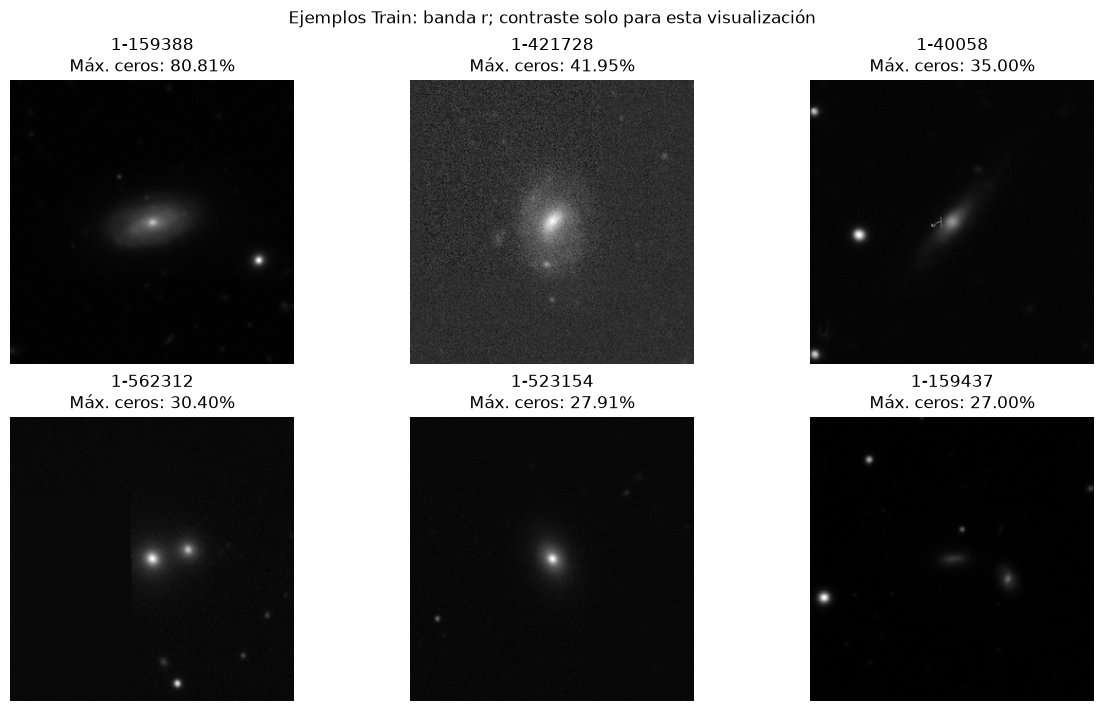

,mangaid,max_ceros_pct,error_log_mstar,error_log_sfr,error_d4000
1156,1-159388,80.807778,0.083902,0.098402,0.034812
6261,1-421728,41.952222,0.088484,0.125041,0.018578
5853,1-40058,35.000000,0.072236,0.063207,0.020766
7661,1-562312,30.401111,0.067503,0.082956,0.027228
7237,1-523154,27.914444,0.062852,0.060353,0.027893
1159,1-159437,27.000000,0.087929,0.113955,0.066947
760,1-1437,26.333333,0.061002,0.053044,0.009327
218,1-116087,20.226667,0.080205,0.105338,0.028568
7423,1-547544,15.030000,0.081778,0.078907,0.042250
1515,1-179062,14.243333,0.065569,0.073626,0.031172


In [5]:
muestra = preparar_entradas(muestra, CFG, SALIDA)
auditoria_mapas = auditar_mapas(muestra, CFG, SALIDA)
mostrar_calidad(muestra, CFG, SALIDA)


## 6 · Representación de las bandas y normalización

Preparamos dos representaciones a partir de los mismos recortes. En la primera construimos una imagen RGB mediante Lupton, con R=z, G=r y B=g. Utilizamos `Q=8`, `stretch=0.5` y `minimum=0`; generamos valores uint8 y después los convertimos a float32 en el intervalo de 0 a 1. Mantuvimos esa configuración de visualización fija para que el contraste no cambiara entre galaxias. Posteriormente aplicamos las medias [0.485, 0.456, 0.406] y desviaciones [0.229, 0.224, 0.225] de ImageNet en el orden R, G, B. No aplicamos el recorte automático a 224 píxeles de torchvision.

En la segunda representación conservamos los tres planos g, r y z como valores float32, incluidos los negativos. Comprimimos su rango con la transformación `asinh(f_b / s_b)` y después estandarizamos cada banda. Calculamos `s_b` como el percentil 75 de los valores absolutos de una muestra de píxeles de Train: tomamos 512 posiciones por imagen, de forma determinista, para que todas aportaran el mismo número de muestras. Calculamos después la media y la desviación de las bandas transformadas usando todos los píxeles de Train.

| Decisión | Valor que utilizamos | Motivo |
|---|---|---|
| Compresión de GRZ | asinh | Trabajamos con intensidades de ambos signos y comprimimos valores grandes sin imponer una normalización independiente a cada galaxia. |
| Escala de compresión | Percentil 75 de valores absolutos en Train | Definimos una escala común por banda con un cuantil, sin depender exclusivamente de los valores máximos. |
| Muestreo para esa escala | 512 posiciones por imagen de Train | Limitamos el costo de estimar el cuantil y dimos igual participación a cada galaxia. |
| Normalización de GRZ | Media y desviación poblacional por banda en Train | Colocamos las bandas en escalas numéricas comparables con parámetros compartidos entre galaxias. |
| Normalización de etiquetas y redshift | Media y desviación poblacional en Train | Facilitamos la optimización y equilibramos numéricamente las tres tareas. |

Como referencias orientativas alrededor de estas elecciones, podimos contrastar `Q` de 4 y 12, `stretch` de 0.25 y 1, percentiles 50 y 90, o muestras de 256 y 1 024 píxeles por imagen.

Estandarizamos cada etiqueta mediante `(y − media_Train) / desviacion_Train` e invertimos esa operación al producir las predicciones. Aplicamos el mismo principio al redshift cuando fue predictor. Esta operación modificó la escala numérica, pero no constituyó una corrección astronómica por distancia. 

Ajustamos estas estadísticas con las 7 121 galaxias de Train y las reutilizamos sin cambios en Validation y Test. La transformación asinh no conservó el flujo en sus unidades originales; por ello no tratamos los tensores transformados como mediciones fotométricas. 


In [6]:
ESTADISTICOS = calcular_estadisticos(muestra, CFG, SALIDA)
muestra = preparar_representaciones(muestra, CFG, ESTADISTICOS, SALIDA)
print("Entradas listas:",len(muestra))
print("Estadísticos ajustados con Train:",ESTADISTICOS["n_train"])


Representaciones: 500 / 9299
Representaciones: 1000 / 9299
Representaciones: 1500 / 9299
Representaciones: 2000 / 9299
Representaciones: 2500 / 9299
Representaciones: 3000 / 9299
Representaciones: 3500 / 9299
Representaciones: 4000 / 9299
Representaciones: 4500 / 9299
Representaciones: 5000 / 9299
Representaciones: 5500 / 9299
Representaciones: 6000 / 9299
Representaciones: 6500 / 9299
Representaciones: 7000 / 9299
Representaciones: 7500 / 9299
Representaciones: 8000 / 9299
Representaciones: 8500 / 9299
Representaciones: 9000 / 9299
Representaciones: 9299 / 9299
Entradas listas: 9299
Estadísticos ajustados con Train: 7121


## 7 · Arquitectura, función de pérdida y entrenamiento

Utilizamos ResNet50 con pesos ImageNet1K V1 como extractor de características. Conservamos sus tres canales de entrada y sustituimos la capa clasificadora por una identidad para obtener un vector visual de 2048 componentes. Con esta elección aprovechamos una representación preentrenada y mantuvimos una arquitectura común mientras estudiábamos las variantes.

En B–G conectamos ese vector a tres cabezas, una para `log_mstar`, otra para `log_sfr` y otra para `d4000`. En C, D y E añadimos el redshift estandarizado antes de las cabezas, con lo que cada una recibió 2049 valores. En A construimos un extractor y una cabeza por propiedad. No incorporamos flujos, magnitudes ni colores tabulares adicionales.

Cada cabeza siguió la secuencia `Linear(2048 o 2049, 256) → ReLU → Dropout(0.1) → Linear(256, 1)`. Elegimos 256 unidades para proporcionar capacidad de ajuste a cada tarea y dropout de 0.1 para introducir regularización sin retirar una fracción grande de las activaciones. Dejamos la neurona final sin activación restrictiva, porque realizamos regresión sobre etiquetas estandarizadas. Como candidatos orientativos podríamos contrastar 128 y 512 unidades, así como dropout de 0.05 y 0.20; no contamos en este archivo con métricas de esas alternativas.

La auditoría registró 25 083 203 parámetros para las variantes multitarea con redshift y 25 082 435 para las que no lo utilizaron. A reunió 72 098 499 parámetros entre sus tres redes. Esta diferencia de capacidad formó parte de la comparación entre aprendizaje independiente y compartido.

Adaptamos el extractor en tres etapas:

| Épocas | Parámetros que entrenamos | Razón del calendario |
|---|---|---|
| 1–5 | Cabezas de regresión | Primero adaptamos las salidas nuevas a las etiquetas. |
| 6–15 | Cabezas y `layer4` | Después permitimos que el bloque más profundo ajustara sus características. |
| Desde la 16 | Cabezas y extractor completo | Finalmente adaptamos toda la representación a las imágenes del proyecto. |

Mantuvimos fijas las medias y varianzas acumuladas de BatchNorm para no reestimarlas con los lotes pequeños de este entrenamiento. Sus parámetros afines aprendieron cuando abrimos el bloque correspondiente. Utilizamos tasas iniciales diferentes para las cabezas y el extractor, acumulación de dos lotes y recorte de norma del gradiente a 5, como describimos en la configuración.

En A–D y F entrenamos con MSE. En E y G utilizamos Huber con `delta=1` sobre las etiquetas estandarizadas. Con ese valor, Huber aplica una penalización cuadrática cuando el error absoluto es menor que 1 y una penalización lineal para errores mayores. El umbral equivale a una desviación de Train de cada etiqueta, no a un dex ni a una unidad física común entre las tareas. Elegimos esta escala para disminuir la influencia relativa de residuos grandes conservando una penalización suave cerca de cero. Los valores 0.5 y 2 serían candidatos orientativos menores y mayores, pero aquí solo documentamos `delta=1`.

Promediamos las tres pérdidas en las redes multitarea y asignamos a cada propiedad el mismo peso de 1/3 después de estandarizarla. No aprendimos pesos por incertidumbre ni alimentamos una cabeza con etiquetas o predicciones de otra. Para guardar el mejor estado de cualquier variante usamos siempre el MSE normalizado de Validation, incluso cuando entrenamos con Huber.

Durante el entrenamiento aplicamos giros de 0°, 90°, 180° y 270°, además de reflexiones horizontales y verticales. Realizamos la misma transformación en las tres bandas para conservar su alineación. Elegimos estas operaciones porque cambian la orientación aparente sin necesitar interpolación. Evaluamos Train y Validation sin aumentos; la evaluación posterior en Test también deberá realizarse sin aumentos. Activamos bfloat16 cuando la GPU lo permitió o float16 con escalamiento de gradientes en caso contrario, y realizamos la evaluación en float32.

In [7]:
# MEJORAS M06–M09: multitarea, redshift, ajuste fino progresivo y selección en Validation.
class GalaxiasDataset(Dataset):
    def __init__(self,tabla,especificacion,stats,entrenamiento=False,semilla=42,epoca=0):
        self.tabla=tabla.reset_index(drop=True);self.e=especificacion;self.s=stats
        self.train=entrenamiento;self.seed=semilla;self.epoch=epoca
    def __len__(self): return len(self.tabla)
    def __getitem__(self,i):
        r=self.tabla.iloc[i]
        x=np.load(r['ruta_'+self.e['entrada']],allow_pickle=False).copy()
        if self.train:
            # Los mismos aumentos por ID/época/semilla en todas las variantes; rotaciones sin interpolación.
            seed=int(hashlib.sha256(f'{self.seed}:{self.epoch}:{r.mangaid}'.encode()).hexdigest()[:16],16)
            rng=np.random.default_rng(seed)
            x=np.rot90(x,int(rng.integers(0,4)),axes=(1,2))
            if rng.random()<.5: x=x[:,:,::-1]
            if rng.random()<.5: x=x[:,::-1,:]
        if self.e['entrada']=='RGB':
            x=(x-np.array(self.s['rgb_media'],np.float32)[:,None,None])/np.array(self.s['rgb_std'],np.float32)[:,None,None]
        x=np.ascontiguousarray(x,dtype=np.float32)
        y=r[OBJETIVOS].to_numpy(dtype=np.float32)
        y=(y-np.array(self.s['y_media'],np.float32))/np.array(self.s['y_std'],np.float32)
        # Sin redshift predictor: marcador cero para mantener la interfaz; forward lo ignora.
        z=(np.array([(float(r.redshift)-self.s['z_media'])/self.s['z_std']],np.float32)
           if self.e['redshift'] else np.zeros(1,dtype=np.float32))
        if not (np.isfinite(x).all() and np.isfinite(y).all() and np.isfinite(z).all()): raise ValueError('Entrada no finita '+r.mangaid)
        return torch.from_numpy(x),torch.from_numpy(z),torch.from_numpy(y)

class RedPropiedades(nn.Module):
    def __init__(self,cfg,con_redshift=False,n_salidas=3,preentrenada=True):
        super().__init__();self.con_redshift=con_redshift
        pesos=models.ResNet50_Weights.IMAGENET1K_V1 if preentrenada else None
        if preentrenada and cfg['pesos_imagenet_local']:
            self.backbone=models.resnet50(weights=None)
            state=torch.load(Path(cfg['pesos_imagenet_local']).expanduser(),map_location='cpu',weights_only=True)
            self.backbone.load_state_dict(state,strict=True)
        else: self.backbone=models.resnet50(weights=pesos)
        n=self.backbone.fc.in_features;self.backbone.fc=nn.Identity()
        # Siempre tres canales. No se reemplaza la primera convolución preentrenada.
        self.salidas=nn.ModuleList([nn.Sequential(nn.Linear(n+int(con_redshift),256),nn.ReLU(),
                                    nn.Dropout(.1),nn.Linear(256,1)) for _ in range(n_salidas)])
    def forward(self,x,z):
        f=self.backbone(x)
        if self.con_redshift: f=torch.cat([f,z],dim=1)
        return torch.cat([h(f) for h in self.salidas],dim=1)

def fase_entrenamiento(epoca,cfg):
    if epoca<=cfg['epocas_solo_salidas']: return 'salidas'
    if epoca<=cfg['epocas_hasta_abrir_toda_red']: return 'layer4'
    return 'toda_red'

def aplicar_fase(modelo,epoca,cfg):
    fase=fase_entrenamiento(epoca,cfg)
    for nombre,p in modelo.backbone.named_parameters():
        p.requires_grad=(fase=='toda_red' or (fase=='layer4' and nombre.startswith('layer4.')))
    for p in modelo.salidas.parameters(): p.requires_grad=True
    modelo.train()
    # Congelamos medias/varianzas BN en todas las fases. Los parámetros afines siguen el bloque.
    for m in modelo.backbone.modules():
        if isinstance(m,nn.modules.batchnorm._BatchNorm): m.eval()
    return fase

def hacer_loader(tabla,e,s,cfg,seed,epoch=0,train=False):
    gen=torch.Generator().manual_seed(seed+epoch*100003)
    ds=GalaxiasDataset(tabla,e,s,train,seed,epoch)
    return DataLoader(ds,batch_size=cfg['batch_size'],shuffle=train,drop_last=False,
                      num_workers=cfg['num_workers'],pin_memory=bool(cfg['usar_gpu']),generator=gen)

def estado_rng():
    ns=np.random.get_state()
    return dict(python=random.getstate(),numpy=[ns[0],ns[1].tolist(),ns[2],ns[3],ns[4]],
                torch=torch.get_rng_state(),cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [])

def restaurar_rng(s):
    random.setstate(s['python']);n=s['numpy'];np.random.set_state((n[0],np.array(n[1],dtype=np.uint32),n[2],n[3],n[4]))
    torch.set_rng_state(s['torch'])
    if torch.cuda.is_available() and s['cuda']: torch.cuda.set_rng_state_all(s['cuda'])

def a_cpu(x):
    if torch.is_tensor(x): return x.detach().cpu().clone()
    if isinstance(x,dict): return {k:a_cpu(v) for k,v in x.items()}
    if isinstance(x,list): return [a_cpu(v) for v in x]
    if isinstance(x,tuple): return tuple(a_cpu(v) for v in x)
    return x

def guardar_estado(payload,carpeta):
    # Un archivo nuevo se verifica ANTES de sustituir el puntero. Se conservan dos generaciones.
    carpeta=Path(carpeta);carpeta.mkdir(parents=True,exist_ok=True)
    p=carpeta/f'estado_{payload["epoca"]:04d}_{uuid.uuid4().hex[:8]}.pt'
    temp=p.with_suffix('.tmp')
    with open(temp,'wb') as f: torch.save(a_cpu(payload),f);f.flush();os.fsync(f.fileno())
    comprobado=torch.load(temp,map_location='cpu',weights_only=True)
    if comprobado['firma']!=payload['firma'] or comprobado['epoca']!=payload['epoca']: raise RuntimeError('Checkpoint no verificado.')
    del comprobado;os.replace(temp,p)
    pointer=carpeta/'reanudacion.json';anterior=json.loads(pointer.read_text()) if pointer.is_file() else {}
    actual=dict(archivo=p.name,sha256=sha_archivo(p),epoca=payload['epoca'])
    # No se borra nada hasta que el nuevo puntero está escrito.
    respaldo=None
    for d in [anterior.get('actual'),anterior.get('anterior')]:
        if d and (carpeta/d['archivo']).is_file() and sha_archivo(carpeta/d['archivo'])==d['sha256']:
            respaldo=d;break
    nuevo=dict(actual=actual,anterior=respaldo)
    escribir_json(nuevo,pointer)
    conservar={x['archivo'] for x in nuevo.values() if x}
    for viejo in carpeta.glob('estado_*.pt'):
        if viejo.name not in conservar: viejo.unlink()

def cargar_estado(carpeta,identidad):
    pointer=Path(carpeta)/'reanudacion.json'
    if not pointer.is_file(): return None
    datos=json.loads(pointer.read_text());problemas=[]
    for cual in ['actual','anterior']:
        d=datos.get(cual)
        if not d: continue
        p=Path(carpeta)/d['archivo']
        try:
            if not p.is_file() or sha_archivo(p)!=d['sha256']: raise ValueError('Checksum incorrecto o archivo ausente.')
            s=torch.load(p,map_location='cpu',weights_only=True)
        except Exception as e: problemas.append(str(e));continue
        if s['firma']!=identidad: raise ValueError('Cambió la definición del experimento; no se mezcla un checkpoint distinto.')
        if cual=='anterior': print('Recuperada generación anterior verificada, época',s['epoca'])
        return s
    raise RuntimeError('No hay checkpoint recuperable: '+str(problemas))

def guardar_mejor(state,path):
    path=Path(path);tmp=path.with_suffix('.tmp')
    with open(tmp,'wb') as f: torch.save(state,f);f.flush();os.fsync(f.fileno())
    torch.load(tmp,map_location='cpu',weights_only=True);os.replace(tmp,path)
    escribir_json({'sha256':sha_archivo(path)},path.with_suffix('.json'))

def evaluar_normalizado(modelo,loader,indices,device):
    modelo.eval();preds=[];ys=[]
    with torch.inference_mode():
        for x,z,y in loader:
            p=modelo(x.to(device,non_blocking=True),z.to(device,non_blocking=True)).float().cpu().numpy()
            yy=y[:,indices].numpy()
            if not np.isfinite(p).all(): raise FloatingPointError('Predicción no finita durante evaluación.')
            preds.append(p);ys.append(yy)
    p=np.concatenate(preds);y=np.concatenate(ys)
    return float(np.mean((p-y)**2)),p,y

def entrenar_un_modelo(tabla,e,s,cfg,seed,indices,carpeta,identidad):
    # Bloqueo local: evita escribir el mismo experimento desde dos notebooks simultáneamente.
    import fcntl
    carpeta=Path(carpeta);carpeta.mkdir(parents=True,exist_ok=True)
    with open(carpeta/'ejecucion.lock','a') as lock:
        try: fcntl.flock(lock,fcntl.LOCK_EX|fcntl.LOCK_NB)
        except BlockingIOError: raise RuntimeError('Este experimento ya está ejecutándose en otro proceso.')
        return _entrenar(tabla,e,s,cfg,seed,indices,carpeta,identidad)

def _entrenar(tabla,e,s,cfg,seed,indices,carpeta,identidad):
    if cfg['usar_gpu'] and not torch.cuda.is_available(): raise RuntimeError('No se detecta CUDA en este kernel. Revisa el entorno antes del entrenamiento completo.')
    device=torch.device('cuda' if cfg['usar_gpu'] else 'cpu')
    previo=cargar_estado(carpeta,identidad)
    if previo and previo['terminado']:
        guardar_mejor(dict(firma=identidad,epoca=previo['mejor_epoca'],modelo=previo['mejor_modelo']),carpeta/'mejor.pt')
        print('Entrenamiento ya completo:',carpeta.name,'| mejor época',previo['mejor_epoca'])
        return
    fijar_semilla(seed)
    modelo=RedPropiedades(cfg,e['redshift'],len(indices),preentrenada=previo is None).to(device)
    opt=torch.optim.AdamW([{'params':modelo.backbone.parameters(),'lr':cfg['lr_backbone']},
                           {'params':modelo.salidas.parameters(),'lr':cfg['lr_salidas']}],weight_decay=cfg['weight_decay'])
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='min',factor=.5,patience=cfg['paciencia_lr'],min_lr=1e-7)
    amp=bool(cfg['precision_mixta'] and device.type=='cuda')
    amp_dtype=torch.bfloat16 if amp and torch.cuda.is_bf16_supported() else torch.float16
    usar_scaler=amp and amp_dtype==torch.float16
    scaler=torch.amp.GradScaler('cuda',enabled=usar_scaler)
    state=dict(firma=identidad,epoca=0,terminado=False,mejor_val=float('inf'),referencia_parada=float('inf'),
               mejor_epoca=0,mejor_modelo=None,sin_mejora=0,historial=[])
    if previo:
        state=previo;modelo.load_state_dict(state['modelo']);opt.load_state_dict(state['optimizador'])
        scheduler.load_state_dict(state['scheduler']);scaler.load_state_dict(state['scaler'])
        restaurar_rng(state['rng']);print('Reanudando después de época',state['epoca'],flush=True)
    tr=tabla.loc[tabla.particion.eq('Train')];va=tabla.loc[tabla.particion.eq('Validation')]
    lv=hacer_loader(va,e,s,cfg,seed,train=False)
    perdida=nn.MSELoss(reduction='none') if e['perdida']=='MSE' else nn.HuberLoss(delta=cfg['huber_delta'],reduction='none')
    def persistir():
        state.update(modelo=a_cpu(modelo.state_dict()),optimizador=a_cpu(opt.state_dict()),
                     scheduler=scheduler.state_dict(),scaler=scaler.state_dict(),rng=estado_rng())
        guardar_estado(state,carpeta)
    if previo is None: persistir();print('Inicialización recuperable guardada.',flush=True)
    for epoca in range(state['epoca']+1,cfg['max_epocas']+1):
        inicio=time.monotonic();fase=aplicar_fase(modelo,epoca,cfg)
        if epoca in [1,cfg['epocas_solo_salidas']+1,cfg['epocas_hasta_abrir_toda_red']+1]:
            auditoria=pd.DataFrame([dict(nombre=n,entrenable=p.requires_grad,parametros=p.numel())
                                   for n,p in modelo.named_parameters()])
            escribir_csv(auditoria,carpeta/f'capas_{fase}.csv')
            print('Fase:',fase,'| parámetros entrenables:',int(auditoria.loc[auditoria.entrenable,'parametros'].sum()),flush=True)
        if device.type=='cuda': torch.cuda.reset_peak_memory_stats(device)
        lt=hacer_loader(tr,e,s,cfg,seed,epoca,True)
        suma=0.;vistos=0;omitidas_amp=0;opt.zero_grad(set_to_none=True)
        acc=cfg['acumulacion'];bs=cfg['batch_size']
        for paso,(x,z,y) in enumerate(lt):
            if paso%acc==0: n_ventana=min(acc*bs,len(tr)-paso*bs)
            x=x.to(device,non_blocking=True);z=z.to(device,non_blocking=True);y=y[:,indices].to(device,non_blocking=True)
            with torch.autocast(device_type=device.type,dtype=amp_dtype,enabled=amp):
                p=modelo(x,z);por_imagen=perdida(p,y).mean(dim=1);loss=por_imagen.sum()/n_ventana
            if not torch.isfinite(loss): raise FloatingPointError('Pérdida no finita. Reanuda desde la última época completa después de revisar datos/configuración.')
            scaler.scale(loss).backward();suma+=float(por_imagen.detach().sum());vistos+=len(x)
            if (paso+1)%acc==0 or paso+1==len(lt):
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_([q for q in modelo.parameters() if q.requires_grad],cfg['grad_clip'],error_if_nonfinite=not usar_scaler)
                escala_anterior=scaler.get_scale()
                scaler.step(opt);scaler.update()
                omitidas_amp+=int(usar_scaler and scaler.get_scale()<escala_anterior)
                opt.zero_grad(set_to_none=True)
            if (paso+1)%100==0: print(f'Época {epoca}, lote {paso+1}/{len(lt)}',flush=True)
        val,_,_=evaluar_normalizado(modelo,lv,indices,device)
        # Mejor checkpoint: mínimo exacto. Parada: mejora mínima predefinida para evitar ruido numérico.
        if val<state['mejor_val']:
            state.update(mejor_val=val,mejor_epoca=epoca,mejor_modelo=a_cpu(modelo.state_dict()))
        if val<state['referencia_parada']-cfg['mejora_minima']:
            state['referencia_parada']=val;state['sin_mejora']=0
        else: state['sin_mejora']+=1
        if epoca<cfg['min_epocas_antes_parada']: state['sin_mejora']=0
        if epoca>cfg['epocas_solo_salidas']: scheduler.step(val)
        state['epoca']=epoca
        state['historial'].append(dict(epoca=epoca,fase=fase,loss_train=suma/vistos,mse_validation_normalizado=val,
          lr_backbone=opt.param_groups[0]['lr'],lr_salidas=opt.param_groups[1]['lr'],
          segundos=time.monotonic()-inicio,actualizaciones_omitidas_amp=omitidas_amp,
          memoria_gpu_GiB=torch.cuda.max_memory_allocated(device)/1024**3 if device.type=='cuda' else 0.))
        state['terminado']=epoca==cfg['max_epocas'] or state['sin_mejora']>=cfg['paciencia']
        persistir();escribir_csv(pd.DataFrame(state['historial']),carpeta/'historial.csv')
        print(f'Época {epoca} | {fase} | pérdida Train {suma/vistos:.5f} | MSE normalizado Validation {val:.5f} | mejor {state["mejor_epoca"]}',flush=True)
        if state['terminado']: break
    guardar_mejor(dict(firma=identidad,epoca=state['mejor_epoca'],modelo=state['mejor_modelo']),carpeta/'mejor.pt')
    del modelo,opt,previo,state;gc.collect()
    if device.type=='cuda': torch.cuda.empty_cache()

def configuracion_cientifica(cfg):
    keys=['batch_size','acumulacion','num_workers','max_epocas','epocas_solo_salidas',
          'epocas_hasta_abrir_toda_red','lr_salidas','lr_backbone','weight_decay','paciencia',
          'mejora_minima','paciencia_lr','min_epocas_antes_parada','huber_delta','precision_mixta',
          'grad_clip','rgb_Q','rgb_stretch','usar_gpu']
    return {k:cfg[k] for k in keys}

def definir_corrida(tabla,variante,seed,s,cfg,salida):
    e=VARIANTES[variante]
    doc=dict(version=VERSION,variante=variante,especificacion=e,semilla=int(seed),
             configuracion=configuracion_cientifica(cfg),estadisticos=s,
             muestra_sha=firma(tabla[['mangaid','particion',*OBJETIVOS,'redshift','cache_sha256']].to_dict('records')),
             entorno=versiones(),pesos='ImageNet1K V1',
             pesos_local_sha=sha_archivo(cfg['pesos_imagenet_local']) if cfg['pesos_imagenet_local'] else None)
    id_run=firma(doc);carpeta=salida/'corridas'/f'{variante}_s{seed}_{id_run[:10]}'
    carpeta.mkdir(parents=True,exist_ok=True);escribir_json(doc,carpeta/'experimento.json')
    return carpeta,id_run

def entrenar_variante(tabla,variante,seed,s,cfg,salida):
    carpeta,id_run=definir_corrida(tabla,variante,seed,s,cfg,salida);e=VARIANTES[variante]
    grupos=[[0],[1],[2]] if e['arquitectura']=='independiente' else [[0,1,2]]
    for indices in grupos:
        nombre=OBJETIVOS[indices[0]] if len(indices)==1 else 'multitarea'
        print('\n',variante,'| semilla',seed,'|',nombre,flush=True)
        entrenar_un_modelo(tabla,e,s,cfg,seed,indices,carpeta/nombre,firma([id_run,indices]))
    return carpeta

def predecir_corrida(tabla,variante,seed,s,cfg,salida,particion):
    if particion not in ('Train', 'Validation'):
        raise ValueError('Esta etapa solo predice Train y Validation. Test corresponde al modelo final de los seis candidatos.')
    carpeta,id_run=definir_corrida(tabla,variante,seed,s,cfg,salida);e=VARIANTES[variante]
    datos=tabla.loc[tabla.particion.eq(particion)].reset_index(drop=True)
    loader=hacer_loader(datos,e,s,cfg,seed,train=False)
    device=torch.device('cuda' if cfg['usar_gpu'] else 'cpu');pred=np.empty((len(datos),3))
    grupos=[[0],[1],[2]] if e['arquitectura']=='independiente' else [[0,1,2]]
    for ix in grupos:
        nombre=OBJETIVOS[ix[0]] if len(ix)==1 else 'multitarea';p=carpeta/nombre/'mejor.pt'
        sello=json.loads(p.with_suffix('.json').read_text())
        if sha_archivo(p)!=sello['sha256']: raise ValueError('Checkpoint seleccionado alterado: '+str(p))
        state=torch.load(p,map_location='cpu',weights_only=True)
        if state['firma']!=firma([id_run,ix]): raise ValueError('Modelo de otra definición.')
        modelo=RedPropiedades(cfg,e['redshift'],len(ix),False).to(device);modelo.load_state_dict(state['modelo'])
        _,pn,_=evaluar_normalizado(modelo,loader,ix,device)
        pred[:,ix]=pn*np.array(s['y_std'])[ix]+np.array(s['y_media'])[ix]
        del modelo,state;gc.collect()
        if device.type=='cuda': torch.cuda.empty_cache()
    columnas=['mangaid','particion',*OBJETIVOS,*ERRORES,'redshift','r90_arcsec']+[f'ceros_{b}_pct' for b in 'grz']
    out=datos[columnas].copy();out['variante']=variante;out['semilla']=seed
    for j,y in enumerate(OBJETIVOS): out['pred_'+y]=pred[:,j];out['residuo_'+y]=pred[:,j]-out[y]
    escribir_csv(out,carpeta/f'predicciones_{particion}.csv')
    return out,carpeta

## 8 · Métricas y reglas de selección

Evaluamos las predicciones en la escala original de cada etiqueta. Utilizamos MAE para resumir el error absoluto típico, RMSE para dar mayor peso a errores grandes y sesgo, definido como el promedio de predicción menos referencia, para identificar sobreestimación o subestimación. Añadimos la dispersión de residuos, la mediana del error absoluto y R². Interpretamos R² como una medida relativa respecto de la variación de la referencia, no como un porcentaje de exactitud.

Para comparar conjuntamente las tres propiedades calculamos, por tarea, `MSE_normalizado = (RMSE / desviacion_Train)²`. Promediamos esos tres valores dentro de cada semilla y después promediamos las semillas 42, 7 y 2026. Así evitamos sumar directamente errores en dex y errores adimensionales. Verificamos que todas las variantes tuvieran las mismas 1 261 galaxias de Validation y las 63 combinaciones esperadas de variante, semilla y propiedad antes de elegir la menor puntuación global. Este promedio entre semillas decide qué variante representa a ResNet50. Para compararla con los otros cinco algoritmos utilizaremos las métricas de su red individual con semilla 42, incluido el promedio de MSE normalizado de sus tres propiedades.

Dentro de cada entrenamiento guardamos el estado con el menor MSE normalizado de Validation. La tolerancia de 1 × 10⁻⁴ se utilizó únicamente para actualizar el contador de paciencia; no impidió guardar una mejora más pequeña del mejor estado. Impedimos la parada por falta de mejora antes de la época 25 y fijamos una paciencia de 12 épocas. Este mínimo reguló cuándo detener el entrenamiento, no la época que podía resultar seleccionada: el mejor estado podía corresponder a una época anterior.

También examinamos errores por cuartiles de redshift y de las propiedades, con límites calculados en Train. Utilizamos `log(sSFR) < −10.8` como separación descriptiva de actividad y comparamos el diámetro nominal de Petro90 con el campo de 78.6 arcsec cuando estuvo disponible. No usamos esos grupos para excluir objetos ni los presentamos como una clasificación física definitiva. Generamos además gráficas de predicción frente a referencia, residuos frente a redshift e incertidumbre, y galerías de galaxias con errores grandes.

En los contrastes entre variantes calculamos `delta_MAE = MAE_nueva − MAE_referencia` sobre los mismos identificadores. Elegimos 1 000 remuestreos bootstrap por semilla para obtener intervalos descriptivos del 95 %. Ese número ofreció una estimación práctica de la variación por remuestreo; no fue un hiperparámetro de la red. Un delta negativo favoreció a la variante nueva. Mantuvimos cada semilla por separado para no contar tres predicciones de una galaxia como tres observaciones independientes.

La desviación entre semillas describió variación del entrenamiento, mientras que el bootstrap describió variación al remuestrear galaxias de Validation. 

In [8]:
# MEJORA M10: comparación pareada, diagnósticos por población, semillas y Test reservado.
def metricas(y,p):
    y=np.asarray(y,float);p=np.asarray(p,float)
    if not len(y) or not np.isfinite(y).all() or not np.isfinite(p).all(): raise ValueError('Métricas con datos no utilizables.')
    e=p-y;sse=float(np.sum(e*e));den=float(np.sum((y-y.mean())**2))
    return dict(n=len(y),MAE=float(np.abs(e).mean()),RMSE=float(np.sqrt(np.mean(e*e))),
                sesgo=float(e.mean()),sigma_residuos=float(e.std(ddof=0)),
                mediana_error_absoluto=float(np.median(np.abs(e))),R2=1-sse/den if den>0 else np.nan)

def tabla_metricas(pred,s):
    filas=[]
    for j,y in enumerate(OBJETIVOS):
        m=metricas(pred[y],pred['pred_'+y])
        m.update(objetivo=y,unidad='adimensional' if y=='d4000' else 'dex',
                 variante=pred.variante.iloc[0],semilla=int(pred.semilla.iloc[0]),
                 particion=pred.particion.iloc[0],MSE_normalizado=(m['RMSE']/s['y_std'][j])**2)
        filas.append(m)
    return pd.DataFrame(filas)

def diagnosticar_predicciones(pred,train,cfg,destino):
    destino=Path(destino);destino.mkdir(parents=True,exist_ok=True)
    split=pred.particion.iloc[0];grupos=[];extremos=[]
    cortes_z=np.unique(np.quantile(train.redshift,[.25,.5,.75]))
    categor=pd.cut(pred.redshift,[-np.inf,*cortes_z,np.inf],labels=False)
    actividad=(pred.log_sfr-pred.log_mstar).lt(-10.8)
    # -10.8 se conserva como umbral DESCRIPTIVO del diagnóstico anterior; no etiqueta ni filtro de entrenamiento.
    for y in OBJETIVOS:
        cuartiles=np.unique(np.quantile(train[y],[.25,.5,.75]))
        cats=pd.cut(pred[y],[-np.inf,*cuartiles,np.inf],labels=False)
        listados=[('redshift_Train',categor),('propiedad_Train',cats),
                  ('log_sSFR_menor_-10p8',actividad),
                  ('D90_supera_78p6',pd.Series(np.where(pred.r90_arcsec.isna(),'Sin radio',
                         np.where(2*pred.r90_arcsec>cfg['lado_centro']*cfg['escala_arcsec'],'Supera','No supera')),index=pred.index))]
        for variable,etiquetas in listados:
            for grupo,idx in etiquetas.groupby(etiquetas,dropna=False).groups.items():
                d=pred.loc[idx];grupos.append(dict(objetivo=y,variable_grupo=variable,grupo=str(grupo),**metricas(d[y],d['pred_'+y])))
        d=pred.copy();d['error_absoluto']=np.abs(d['pred_'+y]-d[y]);d['objetivo']=y
        extremos.append(d.sort_values('error_absoluto',ascending=False).head(15))
    escribir_csv(pd.DataFrame(grupos),destino/f'metricas_subgrupos_{split}.csv')
    escribir_csv(pd.concat(extremos,ignore_index=True),destino/f'casos_revision_{split}.csv')
    with PdfPages(destino/f'diagnostico_{split}.pdf') as pdf:
        fig,axs=plt.subplots(2,3,figsize=(14,8),layout='constrained')
        for j,y in enumerate(OBJETIVOS):
            p=pred['pred_'+y];e=p-pred[y];lo=min(pred[y].min(),p.min());hi=max(pred[y].max(),p.max())
            axs[0,j].scatter(pred[y],p,s=8,alpha=.4);axs[0,j].plot([lo,hi],[lo,hi],color='black',lw=1)
            axs[0,j].set(xlabel='Referencia '+y,ylabel='Predicción')
            axs[1,j].scatter(pred.redshift,e,s=8,alpha=.4);axs[1,j].axhline(0,color='black',lw=1)
            axs[1,j].set(xlabel='Redshift',ylabel='Predicción − referencia')
        fig.suptitle(f'{pred.variante.iloc[0]} | {split} | semilla {pred.semilla.iloc[0]}')
        pdf.savefig(fig);plt.close(fig)
        fig,axs=plt.subplots(1,3,figsize=(14,4),layout='constrained')
        for j,(y,err) in enumerate(zip(OBJETIVOS,ERRORES)):
            a=pred[err];ok=np.isfinite(a)&a.gt(0)
            axs[j].scatter(a[ok],np.abs(pred.loc[ok,'pred_'+y]-pred.loc[ok,y]),s=9,alpha=.4)
            axs[j].set(xlabel='Incertidumbre registrada '+y,ylabel='Error absoluto');axs[j].set_xscale('log')
        fig.suptitle('Incertidumbre de referencia y error predictivo: cantidades distintas')
        pdf.savefig(fig);plt.close(fig)
    return pd.DataFrame(grupos)

def galeria_errores(pred,tabla,cfg,destino):
    orden=pred.assign(error_sfr=lambda d: np.abs(d.pred_log_sfr-d.log_sfr)).nlargest(6,'error_sfr')
    filas=orden.merge(tabla[['mangaid','ruta_cache']],on='mangaid',validate='one_to_one')
    fig,axs=plt.subplots(2,3,figsize=(12,8),layout='constrained')
    for ax,(_,r) in zip(axs.ravel(),filas.iterrows()):
        rgb=rgb_fijo(np.load(r.ruta_cache,allow_pickle=False),cfg).transpose(1,2,0)
        ax.imshow(rgb,origin='lower');ax.set_axis_off()
        ax.set_title(f'{r.mangaid}\nSFR ref. {r.log_sfr:.2f}; pred. {r.pred_log_sfr:.2f}')
    fig.suptitle('Mayores errores SFR: casos para interpretación, no exclusiones automáticas')
    fig.savefig(Path(destino)/f'galeria_errores_{pred.particion.iloc[0]}.pdf');plt.close(fig)

def graficar_historial(carpeta):
    with PdfPages(Path(carpeta)/'curvas_entrenamiento.pdf') as pdf:
        for p in sorted(Path(carpeta).glob('*/historial.csv')):
            d=pd.read_csv(p);fig,axs=plt.subplots(1,2,figsize=(11,4),layout='constrained')
            axs[0].plot(d.epoca,d.loss_train);axs[0].set(xlabel='Época',ylabel='Pérdida Train (según variante)')
            axs[1].plot(d.epoca,d.mse_validation_normalizado)
            axs[1].axvline(d.loc[d.mse_validation_normalizado.idxmin(),'epoca'],color='black',ls='--')
            axs[1].set(xlabel='Época',ylabel='MSE normalizado Validation')
            fig.suptitle(p.parent.name+' | Train con aumentos; Validation sin aumentos')
            pdf.savefig(fig);plt.close(fig)

def recuperar_desarrollo_guardado(tabla,variante,seed,s,cfg,salida):
    carpeta, _ = definir_corrida(tabla,variante,seed,s,cfg,salida)
    grupos = OBJETIVOS if VARIANTES[variante]['arquitectura']=='independiente' else ['multitarea']
    for grupo in grupos:
        peso = carpeta / grupo / 'mejor.pt'
        sello = peso.with_suffix('.json')
        if not peso.is_file() or not sello.is_file():
            raise RuntimeError('Falta un checkpoint completo para recuperar la corrida: ' + str(peso))
        if sha_archivo(peso) != json.loads(sello.read_text())['sha256']:
            raise ValueError('Checkpoint alterado: ' + str(peso))
    metricas_run = []
    for split in ['Train', 'Validation']:
        archivo = carpeta / f'predicciones_{split}.csv'
        archivo_met = carpeta / f'metricas_{split}.csv'
        if not archivo.is_file() or not archivo_met.is_file():
            raise RuntimeError('Faltan resultados guardados de ' + split + ' en ' + str(carpeta))
        pred = pd.read_csv(archivo, dtype={'mangaid':'string'})
        requeridas = {'mangaid','particion','variante','semilla',*OBJETIVOS,
                      *['pred_'+y for y in OBJETIVOS]}
        if not requeridas.issubset(pred.columns):
            raise ValueError('Predicciones incompletas: ' + str(archivo))
        if (pred.empty or pred.mangaid.isna().any() or pred.mangaid.duplicated().any()
            or not pred.particion.eq(split).all() or not pred.variante.eq(variante).all()
            or not pred.semilla.eq(seed).all()):
            raise ValueError('Identidad incorrecta: ' + str(archivo))
        ref = tabla.loc[tabla.particion.eq(split)].copy()
        ref['mangaid'] = ref.mangaid.astype('string')
        ref = ref.set_index('mangaid').sort_index()
        pred = pred.set_index('mangaid').sort_index()
        if set(pred.index) != set(ref.index):
            raise ValueError('Las galaxias guardadas no coinciden con ' + split)
        for y in OBJETIVOS:
            if not np.allclose(pred[y], ref[y], rtol=0, atol=1e-6):
                raise ValueError('Etiquetas distintas: ' + y)
            if not np.isfinite(pred['pred_'+y].to_numpy(float)).all():
                raise ValueError('Predicciones no finitas: ' + y)
        recalculadas = tabla_metricas(pred.reset_index(),s).set_index('objetivo').reindex(OBJETIVOS)
        registradas = pd.read_csv(archivo_met)
        if (len(registradas)!=len(OBJETIVOS) or registradas.objetivo.duplicated().any()
            or set(registradas.objetivo)!=set(OBJETIVOS)
            or not registradas.particion.eq(split).all()
            or not registradas.variante.eq(variante).all()
            or not registradas.semilla.eq(seed).all()):
            raise ValueError('Métricas de otra corrida: ' + str(archivo_met))
        registradas = registradas.set_index('objetivo').reindex(OBJETIVOS)
        for col in ['n','MAE','RMSE','sesgo','sigma_residuos','mediana_error_absoluto','R2','MSE_normalizado']:
            if not np.allclose(recalculadas[col],registradas[col],rtol=1e-8,atol=1e-10,equal_nan=True):
                raise ValueError('Predicciones y métricas no coinciden: ' + str(archivo_met))
        metricas_run.append(registradas.reset_index())
    print(f'Resultados guardados de Train y Validation recuperados: {variante} | semilla {seed}')
    return pd.concat(metricas_run,ignore_index=True)


def ejecutar_y_evaluar(tabla,variante,seed,s,cfg,salida):
    if cfg.get('evaluar_test',False):
        raise ValueError('Mantén evaluar_test=False; este notebook termina en Validation.')
    if (salida/'test_abierto.json').exists():
        return recuperar_desarrollo_guardado(tabla,variante,seed,s,cfg,salida)
    carpeta=entrenar_variante(tabla,variante,seed,s,cfg,salida);metricas_run=[]
    for split in ['Train','Validation']:
        p,_=predecir_corrida(tabla,variante,seed,s,cfg,salida,split)
        m=tabla_metricas(p,s);escribir_csv(m,carpeta/f'metricas_{split}.csv');metricas_run.append(m)
        diagnosticar_predicciones(p,tabla.loc[tabla.particion.eq('Train')],cfg,carpeta)
        if split=='Validation': galeria_errores(p,tabla,cfg,carpeta)
    graficar_historial(carpeta)
    return pd.concat(metricas_run,ignore_index=True)



def bootstrap_pareado(a,b,seed=42,reps=1000):
    # Diferencia MAE nuevo − referencia; negativa favorece al nuevo. IC descriptivo por galaxia.
    if a.mangaid.duplicated().any() or b.mangaid.duplicated().any(): raise ValueError('Predicciones repetidas; selecciona antes un modelo y una semilla.')
    t=a.merge(b,on=['mangaid','particion'],suffixes=('_nuevo','_ref'),validate='one_to_one')
    filas=[];rng=np.random.default_rng(seed)
    if len(t)<2: raise ValueError('No hay suficientes galaxias comunes.')
    for y in OBJETIVOS:
        if not np.allclose(t[y+'_nuevo'],t[y+'_ref'],rtol=0,atol=1e-6): raise ValueError('Versiones distintas de etiquetas: '+y)
        dif=np.abs(t['pred_'+y+'_nuevo']-t[y+'_nuevo'])-np.abs(t['pred_'+y+'_ref']-t[y+'_ref'])
        d=dif.to_numpy();vals=np.array([d[rng.integers(0,len(d),len(d))].mean() for _ in range(reps)])
        filas.append(dict(objetivo=y,n_comunes=len(t),n_nuevo=len(a),n_referencia=len(b),
                           delta_MAE=float(d.mean()),IC95_inferior=float(np.quantile(vals,.025)),IC95_superior=float(np.quantile(vals,.975))))
    return pd.DataFrame(filas)




def exportar_resultados(salida):
    salida=Path(salida)
    destino=salida/'resultados_DESI_A_G_Train_Validation.zip'
    with zipfile.ZipFile(destino,'w',compression=zipfile.ZIP_DEFLATED) as z:
        for p in salida.rglob('*'):
            if not p.is_file() or p==destino: continue
            rel=p.relative_to(salida)
            if any(x in rel.parts for x in ['cache_grz','representaciones']): continue
            # Excluimos métricas, predicciones, figuras y registros de evaluación Test.
            # Los catálogos conservan sus particiones y los registros de procedencia.
            if any('test' in x.lower() for x in rel.parts): continue
            if p.suffix.lower() in {'.csv','.json','.pdf','.png','.md'}: z.write(p,rel)
    print('Resultados de Train y Validation exportados:',destino)
    try: display(FileLink(os.path.relpath(destino,Path.cwd())))
    except ValueError: pass
    return destino


# Diseño conjunto A–G. Solo consume datos y resultados de esta ejecución.
CONTRASTES_AG = [
    ('A_ind_rgb_mse', 'B_multi_rgb_mse', 'Compartir extractor con RGB'),
    ('B_multi_rgb_mse', 'C_multi_rgb_z_mse', 'Añadir redshift con RGB y MSE'),
    ('C_multi_rgb_z_mse', 'D_multi_grz_z_mse', 'Usar GRZ con redshift y MSE'),
    ('D_multi_grz_z_mse', 'E_multi_grz_z_huber', 'Usar Huber con GRZ y redshift'),
    ('B_multi_rgb_mse', 'F_multi_grz_mse', 'Usar GRZ sin redshift y con MSE'),
    ('F_multi_grz_mse', 'G_multi_grz_huber', 'Usar Huber con GRZ sin redshift'),
    ('F_multi_grz_mse', 'D_multi_grz_z_mse', 'Añadir redshift con GRZ y MSE'),
    ('G_multi_grz_huber', 'E_multi_grz_z_huber', 'Añadir redshift con GRZ y Huber'),
]


def semillas_del_diseno(cfg):
    semillas = [cfg['semilla_inicial'], *cfg['semillas_adicionales']]
    if len(set(semillas)) != len(semillas) or any(type(x) is not int for x in semillas):
        raise ValueError('Las semillas deben ser enteros distintos.')
    return semillas


def planificar_corridas(cfg):
    if len(set(cfg['variantes'])) != len(cfg['variantes']):
        raise ValueError('Hay variantes repetidas en la configuración.')
    filas = []
    for seed in semillas_del_diseno(cfg):
        for v in cfg['variantes']:
            e = VARIANTES[v]
            filas.append(dict(variante=v, semilla=seed, entrada=e['entrada'],
                redshift_predictor=e['redshift'], perdida=e['perdida'],
                redes_individuales=3 if e['arquitectura']=='independiente' else 1))
    return pd.DataFrame(filas)


def validar_metricas_conjuntas(tabla, met, cfg):
    claves = ['variante', 'semilla', 'particion', 'objetivo']
    requeridas = set(claves + ['n', 'MAE', 'RMSE', 'sesgo', 'MSE_normalizado'])
    if not requeridas.issubset(met.columns):
        raise ValueError('Faltan columnas de métricas: ' + str(requeridas-set(met.columns)))
    if met.duplicated(claves).any():
        raise ValueError('Hay métricas duplicadas por variante, semilla, partición y objetivo.')
    esperado = {(v, seed, part, y) for v in cfg['variantes'] for seed in semillas_del_diseno(cfg)
                for part in ['Train', 'Validation'] for y in OBJETIVOS}
    observado = set(met[claves].itertuples(index=False, name=None))
    if observado != esperado:
        raise ValueError('No está completa la matriz A–G/semillas/propiedades/Train–Validation. '
                         f'Faltan {len(esperado-observado)} filas; sobran {len(observado-esperado)}.')
    cols = ['MAE', 'RMSE', 'sesgo', 'MSE_normalizado']
    if not np.isfinite(met[cols].to_numpy(float)).all():
        raise ValueError('Hay métricas no finitas.')
    if met[['MAE', 'RMSE', 'MSE_normalizado']].lt(0).any().any():
        raise ValueError('Una métrica de error no puede ser negativa.')
    for part in ['Train', 'Validation']:
        if not met.loc[met.particion.eq(part), 'n'].eq(int(tabla.particion.eq(part).sum())).all():
            raise ValueError('Conteos distintos de galaxias en ' + part)
    return met


def ejecutar_comparaciones(tabla, s, cfg, salida):
    if cfg.get('evaluar_test',False):
        raise ValueError('Mantén evaluar_test=False; la comparación de candidatos usa Validation.')
    if (salida / 'test_abierto.json').exists():
        # Recuperamos el desarrollo completo sin entrenar ni sobrescribir sus métricas originales.
        recuperadas = [recuperar_desarrollo_guardado(tabla,v,seed,s,cfg,salida)
                       for seed in semillas_del_diseno(cfg) for v in cfg['variantes']]
        met = validar_metricas_conjuntas(tabla,pd.concat(recuperadas,ignore_index=True),cfg)
        return met, list(cfg['variantes'])
    # Todas las variantes se entrenan con todas las semillas; no se descarta ninguna
    # por su posición en el ranking inicial de semilla 42.
    plan = planificar_corridas(cfg)
    escribir_csv(plan, salida / 'plan_corridas_A_G.csv')
    print(f"Plan: {len(plan)} corridas de variante y {int(plan.redes_individuales.sum())} redes individuales.")
    todas = []
    for seed in semillas_del_diseno(cfg):
        for v in cfg['variantes']:
            print(f'\nComparación conjunta: {v} | semilla {seed}', flush=True)
            todas.append(ejecutar_y_evaluar(tabla, v, seed, s, cfg, salida))
            parcial = pd.concat(todas, ignore_index=True)
            escribir_csv(parcial, salida / 'metricas_todas_semillas.csv')
            if seed == cfg['semilla_inicial']:
                escribir_csv(parcial, salida / 'metricas_exploracion.csv')
        if seed == cfg['semilla_inicial']:
            va = parcial.loc[parcial.particion.eq('Validation')]
            ranking = va.groupby('variante', as_index=False).MSE_normalizado.mean().sort_values(
                ['MSE_normalizado', 'variante'])
            escribir_csv(ranking, salida / 'ranking_inicial_Validation.csv')
            print('Ranking inicial descriptivo: todas las variantes continúan con las otras semillas.')
            display(ranking)
    met = validar_metricas_conjuntas(tabla, pd.concat(todas, ignore_index=True), cfg)
    escribir_csv(met, salida / 'metricas_todas_semillas.csv')
    escribir_json(dict(candidatas=cfg['variantes'], semillas=semillas_del_diseno(cfg),
        politica='Todas las variantes con todas las semillas; sin descarte por el ranking inicial'),
        salida / 'candidatas_seleccion.json')
    return met, list(cfg['variantes'])


def cerrar_seleccion(tabla, met, candidatas, s, cfg, salida):
    validar_metricas_conjuntas(tabla, met, cfg)
    if set(candidatas) != set(cfg['variantes']):
        raise ValueError('La selección debe considerar todas las variantes configuradas.')
    d = met.loc[met.particion.eq('Validation')].copy()
    por_semilla = d.groupby(['variante', 'semilla'], as_index=False).MSE_normalizado.mean()
    ranking = por_semilla.groupby('variante').MSE_normalizado.agg(['mean', 'std', 'count']).reset_index()
    ranking = ranking.sort_values(['mean', 'variante']).reset_index(drop=True)
    escribir_csv(por_semilla, salida / 'criterio_por_semilla_Validation.csv')
    escribir_csv(ranking, salida / 'ranking_final_Validation.csv')
    display(ranking)
    ganadora = ranking.iloc[0].variante
    carpeta, id_run = definir_corrida(tabla, ganadora, cfg['semilla_inicial'], s, cfg, salida)
    archivos = sorted(carpeta.glob('*/mejor.pt'))
    cantidad = 3 if VARIANTES[ganadora]['arquitectura']=='independiente' else 1
    if len(archivos) != cantidad:
        raise RuntimeError('Faltan los checkpoints seleccionados de la variante ganadora.')
    seleccion = dict(variante=ganadora, semilla=cfg['semilla_inicial'], firma_corrida=id_run,
        criterio='Media entre semillas del promedio de MSE normalizados por propiedad en Validation',
        variantes_comparadas=list(candidatas), semillas_comparadas=semillas_del_diseno(cfg),
        checkpoints={str(p.relative_to(carpeta)):sha_archivo(p) for p in archivos},
        fecha=datetime.now(timezone.utc).isoformat(), sin_evaluacion_test=True,
        test_consultado_en_fase_previa=cfg['test_consultado_en_fase_previa'],
        fase=cfg['fase'])
    p = salida / 'seleccion_cerrada.json'
    if (salida / 'test_abierto.json').exists():
        existente = json.loads(p.read_text())
        if existente['firma_corrida'] != id_run:
            raise RuntimeError('No se cambia la selección de esta ejecución después de evaluar Test.')
        return existente
    escribir_json(seleccion, p)
    print('Selección conjunta A–G:', ganadora, '| semilla fijada:', cfg['semilla_inicial'])
    print('Las semillas no se promedian para predecir. Test permanece desactivado en esta ejecución.')
    return seleccion


def leer_validation_de_esta_ejecucion(tabla, v, seed, s, cfg, salida):
    carpeta, _ = definir_corrida(tabla, v, seed, s, cfg, salida)
    p = carpeta / 'predicciones_Validation.csv'
    pred = pd.read_csv(p, dtype={'mangaid': 'string'})
    requeridas = {'mangaid', 'particion', 'variante', 'semilla', *OBJETIVOS,
                  *['pred_' + y for y in OBJETIVOS]}
    if not requeridas.issubset(pred.columns):
        raise ValueError('Archivo de predicciones incompleto: ' + str(p))
    if (pred.empty or pred.mangaid.isna().any() or pred.mangaid.duplicated().any()
        or not pred.particion.eq('Validation').all() or not pred.variante.eq(v).all()
        or not pred.semilla.eq(seed).all()):
        raise ValueError('Identidad o partición incorrecta en ' + str(p))
    ref = tabla.loc[tabla.particion.eq('Validation')].set_index('mangaid').sort_index()
    if set(pred.mangaid) != set(ref.index):
        raise ValueError('Las predicciones no contienen exactamente las mismas galaxias de Validation.')
    pred = pred.set_index('mangaid').sort_index()
    for y in OBJETIVOS:
        if not np.allclose(pred[y].to_numpy(float), ref[y].to_numpy(float), rtol=0, atol=1e-6):
            raise ValueError('Etiquetas distintas: ' + y)
        if not np.isfinite(pred['pred_' + y].to_numpy(float)).all():
            raise ValueError('Predicciones no finitas: ' + y)
    return pred.reset_index(), dict(variante=v, semilla=seed, archivo=str(p), sha256=sha_archivo(p))


def comparar_y_resumir(tabla, met, seleccion, s, cfg, salida):
    validar_metricas_conjuntas(tabla, met, cfg)
    va = met.loc[met.particion.eq('Validation')].copy()
    resumen = va.groupby(['variante', 'objetivo', 'unidad'], as_index=False).agg(
        n=('n', 'first'), semillas=('semilla', 'nunique'),
        MAE_media=('MAE', 'mean'), MAE_std=('MAE', 'std'),
        RMSE_media=('RMSE', 'mean'), RMSE_std=('RMSE', 'std'),
        sesgo_medio=('sesgo', 'mean'), R2_medio=('R2', 'mean'),
        MSE_normalizado_medio=('MSE_normalizado', 'mean'))
    escribir_csv(resumen, salida / 'resumen_A_G_Validation.csv')
    escribir_csv(va, salida / 'metricas_A_G_Validation.csv')
    tabla_mae = resumen.pivot(index='variante', columns='objetivo', values='MAE_media').reindex(
        index=cfg['variantes'], columns=OBJETIVOS)
    escribir_csv(tabla_mae.reset_index(), salida / 'tabla_MAE_A_G_Validation.csv')
    print('MAE medio entre las tres semillas, en dex para masa/SFR y adimensional para D4000:')
    display(tabla_mae)
    print('Detalle por propiedad: dispersión entre semillas, no incertidumbre de una galaxia.')
    display(resumen)
    fig, axs = plt.subplots(1, 3, figsize=(15, 4.8), layout='constrained')
    for ax, y in zip(axs, OBJETIVOS):
        d = resumen.loc[resumen.objetivo.eq(y)].set_index('variante').reindex(cfg['variantes'])
        ax.bar([v.split('_')[0] for v in d.index], d.MAE_media,
               yerr=d.MAE_std.fillna(0), capsize=3, color='#315c78')
        ax.set(title=y, xlabel='Variante', ylabel='MAE (' + ('adimensional' if y=='d4000' else 'dex') + ')')
    fig.suptitle('A–G · Validation · media ± desviación entre semillas · misma muestra')
    fig.savefig(salida / 'comparacion_A_G_Validation.pdf')
    plt.show();plt.close(fig)

    # Guardar también la comparación de semilla 42 para distinguirla de la media entre semillas.
    inicial = va.loc[va.semilla.eq(cfg['semilla_inicial'])].copy()
    escribir_csv(inicial, salida / 'comparacion_semilla_inicial_Validation.csv')
    print('Métricas de la semilla fijada para desplegar el modelo:')
    display(inicial[['variante','objetivo','MAE','RMSE','sesgo','R2','MSE_normalizado']])

    predicciones, fuentes = {}, []
    for v in cfg['variantes']:
        for seed in semillas_del_diseno(cfg):
            pred, fuente = leer_validation_de_esta_ejecucion(tabla, v, seed, s, cfg, salida)
            # Verificar que el CSV de métricas y sus predicciones se refieren al mismo resultado.
            recalculadas = tabla_metricas(pred, s).set_index('objetivo').reindex(OBJETIVOS)
            registradas = va.loc[va.variante.eq(v)&va.semilla.eq(seed)].set_index('objetivo').reindex(OBJETIVOS)
            for col in ['MAE','RMSE','sesgo','MSE_normalizado']:
                if not np.allclose(recalculadas[col], registradas[col], rtol=1e-8, atol=1e-10):
                    raise ValueError('Predicciones y métricas no coinciden: ' + v + ' / ' + str(seed))
            predicciones[(v,seed)] = pred
            fuentes.append(fuente)
    escribir_json(fuentes, salida / 'fuentes_comparacion_A_G.json')
    filas = []
    for referencia, nueva, pregunta in CONTRASTES_AG:
        for seed in semillas_del_diseno(cfg):
            d = bootstrap_pareado(predicciones[(nueva,seed)], predicciones[(referencia,seed)],
                                 seed=seed, reps=cfg['bootstrap_repeticiones'])
            d['semilla']=seed;d['referencia']=referencia;d['nueva']=nueva;d['pregunta']=pregunta
            filas.append(d)
    diferencias = pd.concat(filas,ignore_index=True)
    resumen_dif = diferencias.groupby(['referencia','nueva','pregunta','objetivo'],as_index=False).agg(
        delta_MAE_media=('delta_MAE','mean'), delta_MAE_std=('delta_MAE','std'), semillas=('semilla','nunique'))
    escribir_csv(diferencias, salida / 'diferencias_pareadas_Validation.csv')
    escribir_csv(resumen_dif, salida / 'resumen_contrastes_A_G.csv')
    print('Contrastes: delta MAE = nueva − referencia; negativo favorece a nueva.')
    display(resumen_dif)

    train=tabla.loc[tabla.particion.eq('Train')];valid=tabla.loc[tabla.particion.eq('Validation')]
    filas=[dict(objetivo=y,**metricas(valid[y],np.full(len(valid),train[y].median()))) for y in OBJETIVOS]
    escribir_csv(pd.DataFrame(filas), salida / 'baseline_mediana_Validation.csv')
    lineas=['# Comparación conjunta A–G','',
        'Seleccionamos el candidato neuronal con Validation. Completaremos seis candidatos, ajustaremos los dos mejores y evaluaremos en Test únicamente el modelo final.',
        '', f'Variante neuronal seleccionada: {seleccion["variante"]}; semilla fijada: {seleccion["semilla"]}.',
        'Las siete variantes se compararon con las mismas tres semillas. No se construyó un ensamble.',
        'Criterio: promedio de MSE normalizado entre propiedades y luego entre semillas.',
        'Los intervalos bootstrap por galaxia son descriptivos por semilla, no corrigen selección ni dependencia espacial.',
        '', '## MAE medio entre semillas', '', '| Variante | log_mstar (dex) | log_sfr (dex) | D4000 |',
        '|---|---:|---:|---:|']
    for v,row in tabla_mae.iterrows():
        lineas.append('| '+v+' | '+' | '.join(f'{row[y]:.6f}' for y in OBJETIVOS)+' |')
    lineas.extend(['','## Métricas de la variante elegida, semilla fijada',''])
    for _,r in inicial.loc[inicial.variante.eq(seleccion['variante'])].iterrows():
        lineas.append(f'- {r.objetivo}: MAE {r.MAE:.6f}; RMSE {r.RMSE:.6f}; sesgo {r.sesgo:.6f}; R² {r.R2:.6f}.')
    (salida / 'resumen_resultados.md').write_text('\n'.join(lineas),encoding='utf-8')
    return resumen, diferencias

## 9 · Verificaciones antes de entrenar

Antes del entrenamiento comprobamos que el entorno detectara CUDA, que cada entrada tuviera tres canales de 300 × 300 y que las etiquetas fueran finitas. Construimos redes temporales sin descargar pesos para revisar las dimensiones de las cabezas y el número de parámetros. En A, B, F y G comprobamos que modificar el argumento de redshift no cambiara la predicción en modo evaluación; en C, D y E verificamos la concatenación y las 2049 entradas por cabeza.

Revisamos también el calendario de apertura de capas, las semillas y el listado completo de variantes. Confirmamos 21 corridas de variante y 27 redes individuales. Esta verificación comprobó la implementación y permitió detectar inconsistencias antes de invertir tiempo de GPU; no midió la capacidad predictiva de los modelos.


In [9]:
if CFG['usar_gpu'] and not torch.cuda.is_available():
    raise RuntimeError('Este kernel no detecta CUDA. Selecciona el entorno GPU del servidor.')
assert CFG['batch_size'] > 0 and CFG['acumulacion'] > 0
assert CFG['max_epocas'] >= CFG['min_epocas_antes_parada'] > CFG['epocas_hasta_abrir_toda_red'] >= CFG['epocas_solo_salidas']
assert CFG['variantes'] == list(VARIANTES), 'Este diseño conjunto incluye A–G.'
assert semillas_del_diseno(CFG) == [42, 7, 2026]
PLAN_CORRIDAS = planificar_corridas(CFG)
display(PLAN_CORRIDAS)
escribir_csv(PLAN_CORRIDAS, SALIDA / 'plan_corridas_A_G.csv')
print('Corridas de variante:', len(PLAN_CORRIDAS), '| Redes individuales:', int(PLAN_CORRIDAS.redes_individuales.sum()))
tr = muestra.loc[muestra.particion.eq('Train')]
device_revision = torch.device('cuda' if CFG['usar_gpu'] else 'cpu')
revision = []
for variante in CFG['variantes']:
    e = VARIANTES[variante]
    ds = GalaxiasDataset(tr.head(2), e, ESTADISTICOS)
    x,z,y = ds[0]
    assert x.shape == (3,CFG['lado_centro'],CFG['lado_centro']) and torch.isfinite(x).all()
    assert y.shape == (3,) and torch.isfinite(y).all() and torch.isfinite(z).all()
    n_salidas = 1 if e['arquitectura']=='independiente' else 3
    with torch.random.fork_rng(devices=[]):
        modelo_revision = RedPropiedades(CFG,con_redshift=e['redshift'],n_salidas=n_salidas,preentrenada=False)
    modelo_revision = modelo_revision.to(device_revision).eval()
    assert all(c[0].in_features == 2048+int(e['redshift']) for c in modelo_revision.salidas)
    with torch.inference_mode():
        xx = x.unsqueeze(0).to(device_revision)
        zz = z.unsqueeze(0).to(device_revision)
        pred_revision = modelo_revision(xx,zz)
        assert pred_revision.shape == (1,n_salidas) and torch.isfinite(pred_revision).all()
        if not e['redshift']:
            assert torch.equal(z,torch.zeros_like(z))
            assert torch.equal(pred_revision,modelo_revision(xx,zz+1000.))
    n_redes = 3 if e['arquitectura']=='independiente' else 1
    n_parametros = sum(p.numel() for p in modelo_revision.parameters())
    revision.append(dict(variante=variante,entrada=e['entrada'],redshift_predictor=e['redshift'],
        entradas_por_cabeza=2048+int(e['redshift']),redes_por_semilla=n_redes,
        salidas_por_red=n_salidas,parametros_por_red=n_parametros,
        parametros_totales_variante=n_parametros*n_redes))
    del modelo_revision,xx,zz,pred_revision
    gc.collect()
    if device_revision.type=='cuda':torch.cuda.empty_cache()
display(pd.DataFrame(revision))
escribir_csv(pd.DataFrame(revision),SALIDA/'verificacion_arquitecturas_A_G.csv')
print('Verificación técnica completada. La siguiente sección inicia los entrenamientos.')


,variante,semilla,entrada,redshift_predictor,perdida,redes_individuales
0,A_ind_rgb_mse,42,RGB,False,MSE,3
1,B_multi_rgb_mse,42,RGB,False,MSE,1
2,C_multi_rgb_z_mse,42,RGB,True,MSE,1
3,D_multi_grz_z_mse,42,GRZ,True,MSE,1
4,E_multi_grz_z_huber,42,GRZ,True,HUBER,1
5,F_multi_grz_mse,42,GRZ,False,MSE,1
6,G_multi_grz_huber,42,GRZ,False,HUBER,1
7,A_ind_rgb_mse,7,RGB,False,MSE,3
8,B_multi_rgb_mse,7,RGB,False,MSE,1
9,C_multi_rgb_z_mse,7,RGB,True,MSE,1


Corridas de variante: 21 | Redes individuales: 27


,variante,entrada,redshift_predictor,entradas_por_cabeza,redes_por_semilla,salidas_por_red,parametros_por_red,parametros_totales_variante
0,A_ind_rgb_mse,RGB,False,2048,3,1,24032833,72098499
1,B_multi_rgb_mse,RGB,False,2048,1,3,25082435,25082435
2,C_multi_rgb_z_mse,RGB,True,2049,1,3,25083203,25083203
3,D_multi_grz_z_mse,GRZ,True,2049,1,3,25083203,25083203
4,E_multi_grz_z_huber,GRZ,True,2049,1,3,25083203,25083203
5,F_multi_grz_mse,GRZ,False,2048,1,3,25082435,25082435
6,G_multi_grz_huber,GRZ,False,2048,1,3,25082435,25082435


Verificación técnica completada. La siguiente sección inicia los entrenamientos.


## 10 · Entrenamiento y recuperación de las corridas

Entrenamos las siete variantes con semilla 42 y después repetimos el conjunto completo con 7 y 2026. Utilizamos el primer ranking solo como descripción provisional: ninguna alternativa quedó fuera por su resultado inicial. Ejecutamos las redes de forma secuencial para controlar el uso de memoria, con lotes de 16 y acumulación de dos lotes.

Guardamos historiales, métricas, estados del optimizador y del generador aleatorio, además de los pesos de mejor desempeño en Validation. Conservamos estados recuperables al terminar cada época. Cuando retomamos una corrida completa, recuperamos sus resultados; cuando una corrida quedó incompleta, pudimos continuar desde la última época guardada, siempre que coincidieran los datos y la configuración.

Las salidas conservadas documentan la recuperación de los entrenamientos completos de las 27 redes. No corresponden a una nueva ejecución de todas las épocas en la llamada visible. En la variante E recuperamos los mejores estados de las épocas 36, 33 y 28 para las semillas 42, 7 y 2026, respectivamente.

Al recuperar una carpeta cuyo entrenamiento ya cerramos y que tiene un registro posterior de evaluación, leemos únicamente las predicciones guardadas de Train y Validation. Comprobamos sus identificadores, etiquetas, métricas y huellas de los checkpoints, sin volver a entrenar ni cargar resultados de Test. Conservamos los registros originales de la carpeta; si falta algún resultado necesario, detenemos la recuperación para no mezclar ejecuciones.

In [10]:
METRICAS, CANDIDATAS = ejecutar_comparaciones(muestra, ESTADISTICOS, CFG, SALIDA)


Resultados guardados de Train y Validation recuperados: A_ind_rgb_mse | semilla 42
Resultados guardados de Train y Validation recuperados: B_multi_rgb_mse | semilla 42
Resultados guardados de Train y Validation recuperados: C_multi_rgb_z_mse | semilla 42
Resultados guardados de Train y Validation recuperados: D_multi_grz_z_mse | semilla 42
Resultados guardados de Train y Validation recuperados: E_multi_grz_z_huber | semilla 42
Resultados guardados de Train y Validation recuperados: F_multi_grz_mse | semilla 42
Resultados guardados de Train y Validation recuperados: G_multi_grz_huber | semilla 42
Resultados guardados de Train y Validation recuperados: A_ind_rgb_mse | semilla 7
Resultados guardados de Train y Validation recuperados: B_multi_rgb_mse | semilla 7
Resultados guardados de Train y Validation recuperados: C_multi_rgb_z_mse | semilla 7
Resultados guardados de Train y Validation recuperados: D_multi_grz_z_mse | semilla 7
Resultados guardados de Train y Validation recuperados: E_m

## 11 · Comparación de resultados en Validation

Reunimos las métricas de las siete variantes y comprobamos que las predicciones correspondieran a los mismos identificadores y etiquetas. Después calculamos las medias y desviaciones entre semillas, los contrastes pareados y el ranking global. Seleccionamos la variante por su promedio de MSE normalizado, no por una única propiedad ni por la mejor semilla aislada.

Obtuvimos el siguiente orden, donde un valor menor indica mejor desempeño global en Validation:

| Posición | Variante | MSE normalizado medio | Desviación entre semillas |
|---:|---|---:|---:|
| 1 | E · GRZ, redshift y Huber | 0.126881 | 0.001525 |
| 2 | D · GRZ, redshift y MSE | 0.128567 | 0.001937 |
| 3 | C · RGB, redshift y MSE | 0.135500 | 0.003787 |
| 4 | F · GRZ, sin redshift y MSE | 0.178092 | 0.004673 |
| 5 | G · GRZ, sin redshift y Huber | 0.179510 | 0.003670 |
| 6 | B · RGB multitarea, sin redshift y MSE | 0.182370 | 0.003481 |
| 7 | A · RGB independiente, sin redshift y MSE | 0.183782 | 0.001921 |

Con esta regla elegimos E y conservamos su corrida de semilla 42, fijada desde el diseño. La diferencia global entre E y D fue pequeña: no la presentamos como evidencia de una superioridad universal de Huber. Además, D obtuvo un MAE medio de masa ligeramente menor, mientras que E obtuvo los menores MAE medios de SFR y D4000 en Validation.

En las tablas que siguen distinguimos la media entre semillas de las métricas de la corrida de semilla 42. Verificamos que los archivos de predicciones reprodujeran las métricas registradas y guardamos la selección junto con las huellas de los pesos. También calculamos una referencia constante basada en la mediana de Train por propiedad para contextualizar el problema, sin incluirla como una variante neuronal adicional. El archivo `seleccion_cerrada.json` identifica la variante elegida dentro de A–G; no representa la elección del modelo final entre los seis algoritmos.

,variante,mean,std,count
0,E_multi_grz_z_huber,0.126881,0.001525,3
1,D_multi_grz_z_mse,0.128567,0.001937,3
2,C_multi_rgb_z_mse,0.135500,0.003787,3
3,F_multi_grz_mse,0.178092,0.004673,3
4,G_multi_grz_huber,0.179510,0.003670,3
5,B_multi_rgb_mse,0.182370,0.003481,3
6,A_ind_rgb_mse,0.183782,0.001921,3


MAE medio entre las tres semillas, en dex para masa/SFR y adimensional para D4000:


objetivo,log_mstar,log_sfr,d4000
variante,,,
A_ind_rgb_mse,0.185076,0.469093,0.055295
B_multi_rgb_mse,0.184842,0.458793,0.056666
C_multi_rgb_z_mse,0.086285,0.410448,0.055752
D_multi_grz_z_mse,0.081538,0.399603,0.053860
E_multi_grz_z_huber,0.082881,0.396620,0.052947
F_multi_grz_mse,0.181068,0.458739,0.054033
G_multi_grz_huber,0.178870,0.459307,0.054264


Detalle por propiedad: dispersión entre semillas, no incertidumbre de una galaxia.


,variante,objetivo,unidad,n,semillas,MAE_media,MAE_std,RMSE_media,RMSE_std,sesgo_medio,R2_medio,MSE_normalizado_medio
0,A_ind_rgb_mse,d4000,adimensional,1261,3,0.055295,0.000826,0.076262,0.000714,-0.001235,0.895271,0.098750
1,A_ind_rgb_mse,log_mstar,dex,1261,3,0.185076,0.004588,0.243882,0.005123,-0.008642,0.861626,0.142276
2,A_ind_rgb_mse,log_sfr,dex,1261,3,0.469093,0.003475,0.646852,0.010465,0.005256,0.690847,0.310320
3,B_multi_rgb_mse,d4000,adimensional,1261,3,0.056666,0.000606,0.077773,0.000845,0.008554,0.891078,0.102703
4,B_multi_rgb_mse,log_mstar,dex,1261,3,0.184842,0.001664,0.241150,0.001661,-0.011727,0.864744,0.139071
5,B_multi_rgb_mse,log_sfr,dex,1261,3,0.458793,0.007637,0.641643,0.009773,0.003608,0.695812,0.305336
6,C_multi_rgb_z_mse,d4000,adimensional,1261,3,0.055752,0.001003,0.076887,0.001526,0.006222,0.893527,0.100394
7,C_multi_rgb_z_mse,log_mstar,dex,1261,3,0.086285,0.002289,0.112866,0.002969,-0.021765,0.970359,0.030477
8,C_multi_rgb_z_mse,log_sfr,dex,1261,3,0.410448,0.007671,0.609646,0.007718,-0.006036,0.725407,0.275630
9,D_multi_grz_z_mse,d4000,adimensional,1261,3,0.053860,0.000198,0.074974,0.001032,-0.001233,0.898774,0.095447


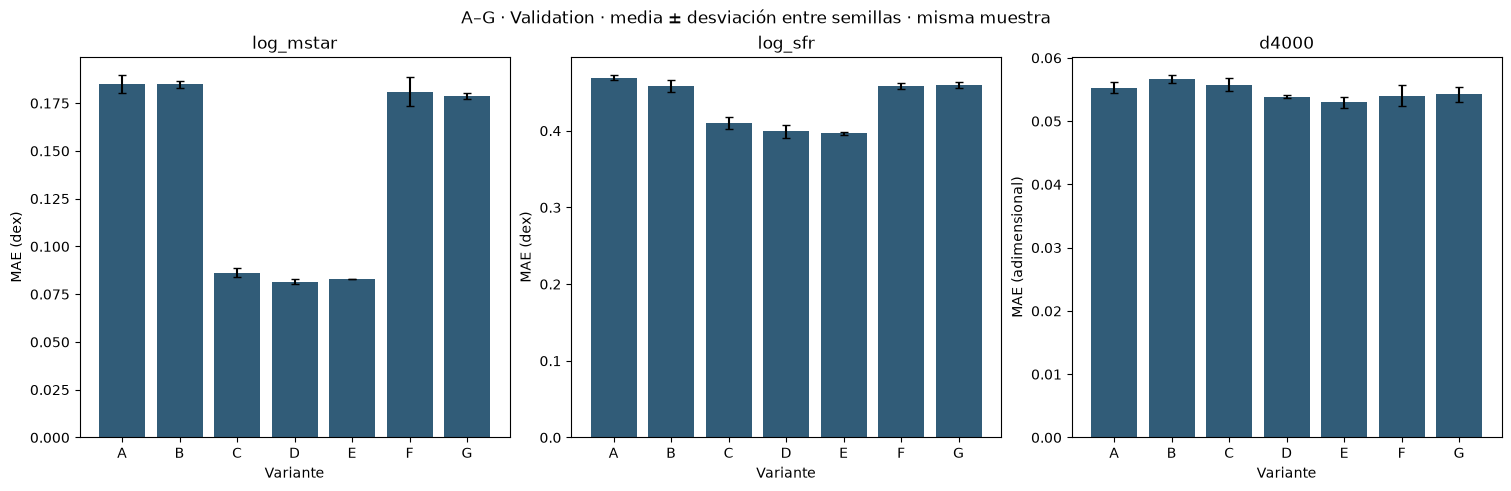

Métricas de la semilla fijada para desplegar el modelo:


,variante,objetivo,MAE,RMSE,sesgo,R2,MSE_normalizado
3,A_ind_rgb_mse,log_mstar,0.184207,0.243531,-0.030113,0.862064,0.141826
4,A_ind_rgb_mse,log_sfr,0.472061,0.638440,-0.032825,0.698888,0.302249
5,A_ind_rgb_mse,d4000,0.056163,0.076990,0.001830,0.893271,0.100636
9,B_multi_rgb_mse,log_mstar,0.183445,0.239673,-0.026316,0.866400,0.137368
10,B_multi_rgb_mse,log_sfr,0.467040,0.648152,-0.045526,0.689657,0.311514
11,B_multi_rgb_mse,d4000,0.057152,0.078740,0.002619,0.888362,0.105264
15,C_multi_rgb_z_mse,log_mstar,0.088748,0.116107,-0.031400,0.968646,0.032238
16,C_multi_rgb_z_mse,log_sfr,0.410122,0.608011,-0.016633,0.726907,0.274124
17,C_multi_rgb_z_mse,d4000,0.055777,0.076754,0.001331,0.893922,0.100022
21,D_multi_grz_z_mse,log_mstar,0.081339,0.108402,-0.007054,0.972670,0.028101


Contrastes: delta MAE = nueva − referencia; negativo favorece a nueva.


,referencia,nueva,pregunta,objetivo,delta_MAE_media,delta_MAE_std,semillas
0,A_ind_rgb_mse,B_multi_rgb_mse,Compartir extractor con RGB,d4000,0.001372,0.000846,3
1,A_ind_rgb_mse,B_multi_rgb_mse,Compartir extractor con RGB,log_mstar,-0.000234,0.005687,3
2,A_ind_rgb_mse,B_multi_rgb_mse,Compartir extractor con RGB,log_sfr,-0.010300,0.004587,3
3,B_multi_rgb_mse,C_multi_rgb_z_mse,Añadir redshift con RGB y MSE,d4000,-0.000915,0.000692,3
4,B_multi_rgb_mse,C_multi_rgb_z_mse,Añadir redshift con RGB y MSE,log_mstar,-0.098557,0.003357,3
5,B_multi_rgb_mse,C_multi_rgb_z_mse,Añadir redshift con RGB y MSE,log_sfr,-0.048345,0.008929,3
6,B_multi_rgb_mse,F_multi_grz_mse,Usar GRZ sin redshift y con MSE,d4000,-0.002634,0.002247,3
7,B_multi_rgb_mse,F_multi_grz_mse,Usar GRZ sin redshift y con MSE,log_mstar,-0.003774,0.007621,3
8,B_multi_rgb_mse,F_multi_grz_mse,Usar GRZ sin redshift y con MSE,log_sfr,-0.000055,0.003952,3
9,C_multi_rgb_z_mse,D_multi_grz_z_mse,Usar GRZ con redshift y MSE,d4000,-0.001891,0.000980,3


In [11]:
SELECCION = cerrar_seleccion(muestra, METRICAS, CANDIDATAS, ESTADISTICOS, CFG, SALIDA)
RESUMEN_A_G, CONTRASTES_A_G_RESULTADOS = comparar_y_resumir(
    muestra, METRICAS, SELECCION, ESTADISTICOS, CFG, SALIDA)


12 · Incorporación del candidato neuronal a la comparación de seis modelos

Cerramos esta etapa con la variante de ResNet50 que obtuvo el mejor desempeño global en Validation. Conservamos una sola red, correspondiente a la semilla 42 de esa variante, para compararla con los demás candidatos. No promediamos las predicciones de las semillas ni contamos las variantes A–G como algoritmos diferentes.

Reuniremos seis modelos individuales de familias distintas y compararemos sus resultados sobre las mismas galaxias de Validation. Seleccionaremos los dos con menor MSE normalizado global, ajustaremos sus hiperparámetros utilizando Train y Validation, y volveremos a compararlos para elegir el modelo individual final. Cuando hayamos fijado esa decisión, realizaremos su evaluación en Test en una etapa separada.

La celda siguiente guarda las métricas de Validation del candidato neuronal y su criterio global. Esta ejecución no genera predicciones, métricas ni diagnósticos de Test. Conservamos sus 917 identificadores dentro de la definición común de la muestra para mantener compatibles las particiones entre notebooks.

In [12]:
# Registramos un único candidato neuronal, evaluado en Validation.
if CFG.get('evaluar_test', False):
    raise ValueError('Esta etapa requiere evaluar_test=False. Test corresponde al modelo final de los seis candidatos.')
validar_metricas_conjuntas(muestra, METRICAS, CFG)
METRICAS_CANDIDATO_NEURONAL = METRICAS.loc[
    METRICAS.particion.eq('Validation')
    & METRICAS.variante.eq(SELECCION['variante'])
    & METRICAS.semilla.eq(SELECCION['semilla'])
].copy().set_index('objetivo').reindex(OBJETIVOS).reset_index()
if (len(METRICAS_CANDIDATO_NEURONAL) != 3
    or METRICAS_CANDIDATO_NEURONAL.MSE_normalizado.isna().any()):
    raise ValueError('Se requieren las tres propiedades del candidato neuronal.')
CRITERIO_CANDIDATO_NEURONAL = float(METRICAS_CANDIDATO_NEURONAL.MSE_normalizado.mean())
escribir_csv(METRICAS_CANDIDATO_NEURONAL, SALIDA / 'candidato_neuronal_Validation.csv')
escribir_json(dict(
    algoritmo='ResNet50', variante=SELECCION['variante'], semilla=SELECCION['semilla'],
    firma_corrida=SELECCION['firma_corrida'], checkpoints=SELECCION['checkpoints'],
    particion_evaluada='Validation',
    n_validation=int(muestra.particion.eq('Validation').sum()),
    MSE_normalizado_global=CRITERIO_CANDIDATO_NEURONAL,
    candidatos_requeridos=6, candidatos_por_ajustar=2,
    estado='Candidato neuronal seleccionado; pendiente comparación de seis algoritmos y ajuste de los dos mejores',
    evaluacion_test_en_esta_etapa=False,
    siguiente_etapa='Elegir el modelo individual final con Validation y evaluarlo después en Test'
), SALIDA / 'candidato_neuronal.json')
display(METRICAS_CANDIDATO_NEURONAL[
    ['objetivo','unidad','n','MAE','RMSE','sesgo','R2','MSE_normalizado']])
print(f'MSE normalizado global de Validation: {CRITERIO_CANDIDATO_NEURONAL:.6f}')
print('Candidato neuronal registrado. Test permanece desactivado en esta etapa.')

,objetivo,unidad,n,MAE,RMSE,sesgo,R2,MSE_normalizado
0,log_mstar,dex,1261,0.082898,0.108829,-0.016994,0.972454,0.028323
1,log_sfr,dex,1261,0.394586,0.597520,-0.010683,0.736249,0.264746
2,d4000,adimensional,1261,0.052342,0.073037,0.007369,0.903949,0.090568


MSE normalizado global de Validation: 0.127879
Candidato neuronal registrado. Test permanece desactivado en esta etapa.


13 · Archivos de resultados de Train y Validation

Exportamos un ZIP con las métricas, predicciones, configuración, selección, auditorías y figuras de Train y Validation. Excluimos los archivos de evaluación de Test que pudieran existir en la carpeta del servidor. Conservamos los catálogos y la definición de las tres particiones para que los otros candidatos utilicen la misma muestra.

Dejamos fuera los FITS, los tensores de caché y los pesos para mantener manejable el archivo. Los checkpoints permanecen en las carpetas de entrenamiento del servidor, donde podemos recuperar las corridas con su configuración original.

| Producto | Información que conservamos |
|---|---|
| `plan_corridas_A_G.csv` y `verificacion_arquitecturas_A_G.csv` | Variantes, semillas, dimensiones y número de parámetros. |
| `configuracion.json`, `estadisticos_Train.json` y `protocolo_A_G.json` | Configuración, transformaciones y procedencia de la ejecución. |
| `metricas_todas_semillas.csv` y `metricas_A_G_Validation.csv` | Resultados de Train y Validation por variante, semilla y propiedad. |
| `resumen_A_G_Validation.csv` y `ranking_final_Validation.csv` | Promedios, dispersión entre semillas y orden de selección. |
| `diferencias_pareadas_Validation.csv` y `resumen_contrastes_A_G.csv` | Comparaciones entre variantes sobre las mismas galaxias. |
| `seleccion_cerrada.json` | Variante neuronal y semilla elegidas, con las huellas de sus checkpoints. |
| `candidato_neuronal_Validation.csv` y `candidato_neuronal.json` | Métricas de la red individual que incorporaremos a la comparación de seis algoritmos. |

Al ejecutar la siguiente celda generamos `resultados_DESI_A_G_Train_Validation.zip` y mostramos su enlace. El notebook conserva los resultados de desarrollo ya obtenidos, pero los FITS, las cachés y los checkpoints necesarios para repetir el entrenamiento permanecen en el servidor.

In [13]:
ZIP_RESULTADOS = exportar_resultados(SALIDA)

Resultados de Train y Validation exportados: /home/a01796921/DESI_experimentos_mejorados/desi_comparacion_A_G_v01/0dc2ac47a31c/resultados_DESI_A_G_Train_Validation.zip


/home/a01796921/DESI_experimentos_mejorados/desi_comparacion_A_G_v01/0dc2ac47a31c/resultados_DESI_A_G_Train_Validation.zip

## 14 · Interpretación y alcance del experimento

Observamos que incorporar redshift produjo la diferencia más clara en la predicción de masa. En los contrastes B→C, F→D y G→E, el MAE medio de Validation pasó de aproximadamente 0.18 dex a valores entre 0.08 y 0.09 dex. También observamos mejoras en SFR, mientras que los cambios en D4000 fueron menores. Estos resultados nos indican que el contexto de redshift resultó útil para nuestra muestra, pero no nos permiten separar por sí solos información física de correlaciones asociadas a su selección.

Al compartir el extractor, A→B, obtuvimos diferencias pequeñas: el MAE medio de masa cambió de 0.185076 a 0.184842 dex y el de SFR de 0.469093 a 0.458793 dex; en D4000 pasó de 0.055295 a 0.056666. Por ello no afirmamos que la multitarea haya mejorado las tres propiedades de forma uniforme. Sí redujimos el número total de parámetros frente a las tres redes independientes.

En Validation, la representación GRZ obtuvo menores MAE medios que RGB tanto en B→F como en C→D. Interpretamos ese resultado como una ventaja de la ruta de representación completa en estas comparaciones. No atribuimos la diferencia exclusivamente a conservar valores negativos o a una transformación específica, porque cambiamos varios aspectos de la representación al mismo tiempo.

El efecto de Huber dependió de la configuración. Con redshift, D→E, redujimos los MAE medios de SFR y D4000, pero aumentamos ligeramente el de masa. Sin redshift, F→G, mejoramos masa y empeoramos ligeramente SFR y D4000. Elegimos E por el criterio global de Validation, no porque Huber hubiera ganado en todos los casos.


## 15 · Referencias de implementación

Consultamos la documentación de los componentes que utilizamos para fundamentar su funcionamiento. Los valores concretos del calendario, las tasas y las cabezas pertenecen a nuestro diseño; no los atribuimos a una recomendación universal de estas fuentes.

- PyTorch. [Transfer Learning for Computer Vision](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html). Distinción entre un extractor congelado y el ajuste de sus pesos.
- Torchvision. [ResNet50 e ImageNet1K V1](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet50.html). Arquitectura, pesos disponibles y normalización de referencia.
- PyTorch. [AdamW](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html). Optimizador y decaimiento de pesos desacoplado.
- PyTorch. [HuberLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.HuberLoss.html). Definición de la pérdida y del umbral delta.
- Astropy. [make_lupton_rgb](https://docs.astropy.org/en/stable/api/astropy.visualization.make_lupton_rgb.html). Construcción de las composiciones RGB.
- Legacy Surveys. [Archivos de DR10](https://www.legacysurvey.org/dr10/files/). Descripción de productos de imagen y mapas auxiliares; esta referencia no sustituye la comprobación del origen de cada FITS.
- PyTorch. [Reproducibilidad](https://docs.pytorch.org/docs/stable/notes/randomness.html). Control de fuentes de aleatoriedad y límites de reproducibilidad entre entornos.

Cerramos el notebook con la variante elegida y sus resultados numéricos.


16 · Candidato neuronal seleccionado y resultados de Validation

Seleccionamos la variante E, `E_multi_grz_z_huber`, para representar a ResNet50 en la comparación de los seis algoritmos. Utilizamos un extractor compartido, imágenes GRZ con asinh y estandarización, redshift concatenado a las características visuales y tres cabezas de regresión entrenadas con Huber de delta 1. Conservamos la semilla 42, cuya mejor época fue la 36, de acuerdo con la regla fijada antes de comparar las variantes.

E obtuvo el menor MSE normalizado global medio en Validation: 0.126881, con una desviación de 0.001525 entre las tres semillas. D quedó en segundo lugar con 0.128567 y una desviación de 0.001937. Este criterio nos permitió elegir la variante neuronal, sin afirmar que fuera superior para cualquier propiedad, métrica o población.

Para compararla con los otros cinco candidatos utilizaremos los resultados de la red individual de semilla 42 sobre las 1 261 galaxias de Validation:

| Propiedad | MAE | RMSE | Sesgo: predicción − referencia | R² | MSE normalizado |
|---|---:|---:|---:|---:|---:|
| Masa estelar, log_mstar | 0.082898 | 0.108829 | −0.016994 | 0.972454 | 0.028323 |
| Formación estelar, log_sfr | 0.394586 | 0.597520 | −0.010683 | 0.736249 | 0.264746 |
| D4000 | 0.052342 | 0.073037 | 0.007369 | 0.903949 | 0.090568 |

Obtuvimos un MSE normalizado global de 0.127879 para esta red individual. Expresamos los errores de masa y SFR en dex, y los de D4000 en unidades adimensionales. Estos valores corresponden a una sola red; no son el resultado de promediar predicciones entre semillas.

Concluimos que E ofreció el mejor balance global de Validation dentro de A–G. Su elección completa el candidato neuronal de esta etapa, mientras que la decisión final del proyecto queda pendiente de comparar los seis algoritmos y ajustar los dos mejores. Después de elegir el modelo individual final con Validation, realizaremos su evaluación en Test por separado.